# Normalize sqY2H consensus scores

This script applies various QA/QC steps and then computes a normalized interaction score. For QA/QC we:

1.   Check whether 6 media controls on each mega-plate meet various condition-specific thresholds
2.   Check for autoactivation mating failures
3.   Adjust consensus score based on autoactivation score and filter if score invalid

In [461]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [462]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = '0.0'
rrs_id = 999999.0

In [463]:
def df_to_dict_variants(df):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
        
    if 'media_control' in df.columns:
        df = df[df['media_control'] == False].copy()
        
    scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
        
    if 'condition_name' in df.columns:
        df = df[df['condition_name'].isin(scoring_conditions)].copy()
    
    cols_to_keep = ['db_orf_id', 'ad_orf_id', 'db_mut_id', 'retest_batch']

    df = df[cols_to_keep].copy()

    df[['db_orf_id', 'ad_orf_id', 'db_mut_id']] = df[['db_orf_id', 'ad_orf_id', 'db_mut_id']].map(float).map(int)
        
    def filter_df(df):
        df = df[(df.ad_orf_id != 0) 
                & (df.db_mut_id != 999999)].copy()
        
        return df
    
    df = filter_df(df)
    
    df_dict = {}
    
    assay_array = ["VUSAPWT1B1","VUSAPWT1B2","VUSAPWT2B1","VUSAPWT6B1"]
    
    for retest_batch in assay_array:
        df_assay = df[df['retest_batch'] == retest_batch]
        df_dict[retest_batch] = {}
        for db_orf_id, df_db in df_assay.sort_values('db_orf_id').groupby('db_orf_id'):
            df_dict[retest_batch][db_orf_id] = {}
            for i, row in df_db.sort_values('db_mut_id').iterrows():
                db_mut_id = row['db_mut_id']
                ad_orf_id = row['ad_orf_id']
                if db_mut_id not in df_dict[retest_batch][db_orf_id].keys():
                    df_dict[retest_batch][db_orf_id][db_mut_id] = {ad_orf_id}
                else:
                    df_dict[retest_batch][db_orf_id][db_mut_id].add(ad_orf_id)
                    
    return df_dict

## Apply all QA/QC thresholds

In [464]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [465]:
scores = pd.read_csv(f"{outputs_dir}/2_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control']]

media_ctrls

,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
12,D01_31,NaN,D01_31,NaN,LWH25,VUSAPWT1B2,True,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98,B01_1,NaN,B01_1,0.0,LWAH1,VUSAPWT2B1,True,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
172,B01_13,NaN,B01_13,NaN,LWH1,VUSAPWT1B2,True,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
278,E01_25,NaN,E01_25,NaN,LWH25,VUSAPWT1B1,True,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
381,B01_13,NaN,B01_13,0.0,LWH10,VUSAPWT6B1,True,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71049,A01_19,NaN,A01_19,NaN,LWA,VUSAPWT1B1,True,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
71059,D01_1,NaN,D01_1,NaN,LWH25,VUSAPWT1B1,True,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
71092,E01_1,NaN,E01_1,NaN,LWAH1,VUSAPWT1B1,True,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
71131,B01_25,NaN,B01_25,NaN,LWA,VUSAPWT1B2,True,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [466]:
scores = pd.read_csv(f"{outputs_dir}/2_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control']]
scores = scores[~scores['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)


dict_before_qc = df_to_dict_variants(scores)

In [467]:
media_ctrls

,db_orf_id,condition_name,retest_batch,consensus_score,scoring_pos,retest_pla,control_384,lower_bound,upper_bound,score_in_bounds
0,D01_31,LWH25,VUSAPWT1B2,4.0,D01,31,G01_G02_H01_H02,3,4,True
1,B01_13,LWH1,VUSAPWT1B2,0.0,B01,13,C01_C02_D01_D02,0,3,True
2,E01_25,LWH25,VUSAPWT1B1,3.0,E01,25,I01_I02_J01_J02,3,4,True
3,B01_13,LWH10,VUSAPWT6B1,0.0,B01,13,C01_C02_D01_D02,0,2,True
4,F01_19,LWH10,VUSAPWT1B2,4.0,F01,19,K01_K02_L01_L02,3,4,True
...,...,...,...,...,...,...,...,...,...,...
595,B01_7,LWH10,VUSAPWT6B1,0.0,B01,7,C01_C02_D01_D02,0,2,True
596,A01_19,LWA,VUSAPWT1B1,0.0,A01,19,A01_A02_B01_B02,0,0,True
597,D01_1,LWH25,VUSAPWT1B1,4.0,D01,1,G01_G02_H01_H02,3,4,True
598,B01_25,LWA,VUSAPWT1B2,0.0,B01,25,C01_C02_D01_D02,0,2,True


In [468]:
scores

ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,edge_group
str,f64,str,f64,str,str,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str
"""0.0""",null,"""3192.0""",9.99999e5,"""LWH25""","""VUSAPWT1B1""",false,2.0,"""empty_ad""",null,null,null,null,null,null,null,null,null,"""1""","""3192.0_999999.0""","""3192.0_999999.0_LWH25_VUSAPWT1…","""0.0_3192.0_999999.0_VUSAPWT1B1""","""0.0_3192.0_VUSAPWT1B1"""
"""4695.0""",null,"""13554.0""",0.0,"""LWAH1""","""VUSAPWT2B1""",false,2.0,"""SMUG1""","""GLYCTK""",null,null,"""ENSG00000168237""",null,null,null,null,"""GLYCTK""","""2""","""13554.0_0.0""","""13554.0_0.0_LWAH1_VUSAPWT2B1""","""4695.0_13554.0_0.0_VUSAPWT2B1""","""4695.0_13554.0_VUSAPWT2B1"""
"""11256.0""",null,"""386.0""",0.0,"""LWH10""","""VUSAPWT1B2""",false,2.0,"""RABEP1""","""STAR""",null,null,"""ENSG00000147465""",null,null,null,null,"""STAR""","""1""","""386.0_0.0""","""386.0_0.0_LWH10_VUSAPWT1B2""","""11256.0_386.0_0.0_VUSAPWT1B2""","""11256.0_386.0_VUSAPWT1B2"""
"""14404.0""",null,"""2713.0""",1005.0,"""LWH1""","""VUSAPWT6B1""",false,0.0,"""SPATA8""","""MLH1""","""Gln701His""","""2103G>C""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",null,3.0,"""MLH1_Gln701His""","""6""","""2713.0_1005.0""","""2713.0_1005.0_LWH1_VUSAPWT6B1""","""14404.0_2713.0_1005.0_VUSAPWT6…","""14404.0_2713.0_VUSAPWT6B1"""
"""4146.0""",null,"""2713.0""",200818.0,"""LWH25""","""VUSAPWT6B1""",false,0.0,"""NELFA""","""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg""","""6""","""2713.0_200818.0""","""2713.0_200818.0_LWH25_VUSAPWT6…","""4146.0_2713.0_200818.0_VUSAPWT…","""4146.0_2713.0_VUSAPWT6B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""8186.0""",null,"""4062.0""",201422.0,"""LW""","""VUSAPWT2B1""",false,4.0,"""CLEC2D""","""PLP1""","""Thr43Ile""","""128C>T""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,1.0,"""PLP1_Thr43Ile""","""2""","""4062.0_201422.0""","""4062.0_201422.0_LW_VUSAPWT2B1""","""8186.0_4062.0_201422.0_VUSAPWT…","""8186.0_4062.0_VUSAPWT2B1"""
"""54341.0""",null,"""2713.0""",200850.0,"""LWAH1""","""VUSAPWT1B1""",false,null,"""PTPN3""","""MLH1""","""Ser295Thr""","""884G>C""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,3.0,"""MLH1_Ser295Thr""","""1""","""2713.0_200850.0""","""2713.0_200850.0_LWAH1_VUSAPWT1…","""54341.0_2713.0_200850.0_VUSAPW…","""54341.0_2713.0_VUSAPWT1B1"""
"""54668.0""",null,"""70497.0""",3851.0,"""LWH10""","""VUSAPWT1B1""",false,2.0,"""KRT40""","""AGXT""","""Ser221Pro""","""661T>C""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ser221Pro""","""1""","""70497.0_3851.0""","""70497.0_3851.0_LWH10_VUSAPWT1B…","""54668.0_70497.0_3851.0_VUSAPWT…","""54668.0_70497.0_VUSAPWT1B1"""


<Axes: title={'center': 'WT consensus manual scores'}, ylabel='Frequency'>

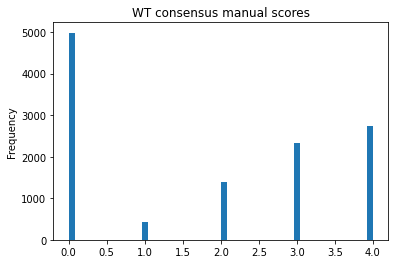

In [469]:
scores_pd = scores.to_pandas()
scores_pd[scores_pd['db_mut_id'] == 0].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores')

In [470]:
scores_pd = scores.to_pandas()
scores_pd[
    (scores_pd.ad_orf_id == '12626.0') &
    (scores_pd.db_orf_id == '9905.0') #&
    # (scores_pd.db_mut_id == 215290)
    ]

,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,edge_group
16,12626.0,NaN,9905.0,0.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,None,None,ENSG00000039650,None,None,NaN,NaN,PNKP,1,9905.0_0.0,9905.0_0.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_0.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
14873,12626.0,NaN,9905.0,216950.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWA_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
16311,12626.0,NaN,9905.0,216952.0,LWH10,VUSAPWT1B2,False,3.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
22862,12626.0,NaN,9905.0,0.0,LWH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,None,None,ENSG00000039650,None,None,NaN,NaN,PNKP,1,9905.0_0.0,9905.0_0.0_LWH1_VUSAPWT1B2,12626.0_9905.0_0.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
25293,12626.0,NaN,9905.0,0.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,None,None,ENSG00000039650,None,None,NaN,NaN,PNKP,1,9905.0_0.0,9905.0_0.0_LWA_VUSAPWT1B2,12626.0_9905.0_0.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
25460,12626.0,NaN,9905.0,216952.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
27469,12626.0,NaN,9905.0,0.0,LW,VUSAPWT1B2,False,NaN,CNTROB,PNKP,None,None,ENSG00000039650,None,None,NaN,NaN,PNKP,1,9905.0_0.0,9905.0_0.0_LW_VUSAPWT1B2,12626.0_9905.0_0.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
29606,12626.0,NaN,9905.0,216950.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
30394,12626.0,NaN,9905.0,216950.0,LWH10,VUSAPWT1B2,False,4.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2
30774,12626.0,NaN,9905.0,216952.0,LWH25,VUSAPWT1B2,False,3.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH25_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2


In [471]:
print('After mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())



# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 2)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print('After mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())


dict_after_db_groups = df_to_dict_variants(scores)

# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print('After mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())


dict_after_db_conditions = df_to_dict_variants(scores)

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 2)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

dict_after_mating = df_to_dict_variants(scores)

print('After mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())


# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).rename({"consensus_score": "aa_score"})

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group")

scores = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
    ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print('After mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())


dict_after_aa = df_to_dict_variants(scores)

After mating failure LW:
(71490, 23)
ppis 8451
After mating failure LW:
(71130, 23)
ppis 8425
After mating failure LW:
(71130, 23)
ppis 8425
After mating failure LW:
(65070, 23)
ppis 7600
After mating failure LW:
(39460, 25)
ppis 7367


In [472]:
print(aa_db_group_mating_failures)
print(len(aa_db_group_mating_failures))
print(aa_db_group_tech_failures)
print(len(aa_db_group_tech_failures))
print(mating_failures)
print(len(mating_failures))

['281.0_29.0', '2920.0_214415.0', '636.0_999999.0', '13571.0_218098.0', '8416.0_216642.0', '11435.0_999999.0', '100016069.0_2637.0', '100016069.0_2620.0', '100016069.0_2624.0', '100016069.0_2638.0', '55222.0_999999.0', '100016069.0_2629.0']
12
[]
0
['100000476.0_2713.0_462.0_VUSAPWT1B1', '56547.0_52920.0_2667.0_VUSAPWT2B1', '10677.0_7675.0_202587.0_VUSAPWT2B1', '71155.0_3535.0_0.0_VUSAPWT6B1', '100000407.0_2803.0_200937.0_VUSAPWT1B2', '14232.0_4062.0_201431.0_VUSAPWT2B1', '56547.0_52920.0_2677.0_VUSAPWT2B1', '54341.0_2713.0_704.0_VUSAPWT1B1', '2758.0_5723.0_0.0_VUSAPWT2B1', '9501.0_5723.0_201966.0_VUSAPWT2B1', '1198.0_56360.0_999999.0_VUSAPWT2B1', '14596.0_7323.0_216369.0_VUSAPWT2B1', '56547.0_52920.0_2683.0_VUSAPWT2B1', '13423.0_4765.0_999999.0_VUSAPWT2B1', '4761.0_2713.0_461.0_VUSAPWT1B1', '4105.0_13939.0_204115.0_VUSAPWT1B2', '54043.0_13295.0_218062.0_VUSAPWT2B1', '56547.0_52920.0_218637.0_VUSAPWT2B1', '2615.0_7652.0_1820.0_VUSAPWT2B1', '14596.0_4062.0_201428.0_VUSAPWT2B1', '72048.0

In [473]:
scores_pd = scores.to_pandas()
scores_pd[
    (scores_pd.ad_orf_id == '12626.0') &
    (scores_pd.db_orf_id == '9905.0') #&
    # (scores_pd.db_mut_id == 215290)
    ]

,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,edge_group,aa_score,adjusted_score
8180,12626.0,NaN,9905.0,216950.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWA_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,0.0
8957,12626.0,NaN,9905.0,216952.0,LWH10,VUSAPWT1B2,False,3.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,3.0
13987,12626.0,NaN,9905.0,216952.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,0.0
16226,12626.0,NaN,9905.0,216950.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,0.0
16674,12626.0,NaN,9905.0,216950.0,LWH10,VUSAPWT1B2,False,4.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,4.0
16905,12626.0,NaN,9905.0,216952.0,LWH25,VUSAPWT1B2,False,3.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH25_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,3.0
23358,12626.0,NaN,9905.0,216952.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWA_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,0.0
26007,12626.0,NaN,9905.0,216952.0,LWH1,VUSAPWT1B2,False,4.0,CNTROB,PNKP,Glu326Lys,976G>A,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH1_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,4.0
26547,12626.0,NaN,9905.0,216950.0,LWH25,VUSAPWT1B2,False,3.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH25_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,3.0
29672,12626.0,NaN,9905.0,216950.0,LWH1,VUSAPWT1B2,False,4.0,CNTROB,PNKP,Pro20Ser,58C>T,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,12626.0_9905.0_VUSAPWT1B2,0.0,4.0


In [474]:
# split rrs & wt scores
rrs_scores = scores.filter(pl.col('db_mut_id') == rrs_id).filter(pl.col("condition_name") == "LWH1")
rrs_count_batch = rrs_scores.group_by(["retest_batch", "adjusted_score"]).agg(pl.len()).pivot(
    values="len", on="adjusted_score", index="retest_batch"
).select(["retest_batch", "0.0", "1.0", "2.0", "3.0", "4.0"])
print(rrs_count_batch)

wt_scores = scores.filter(pl.col('db_mut_id') == 0.0).filter(pl.col("condition_name") == "LWH1")
wt_count_batch = wt_scores.group_by(["retest_batch", "adjusted_score"]).agg(pl.len()).pivot(
    values="len", on="adjusted_score", index="retest_batch"
).select(["retest_batch", "0.0", "1.0", "2.0", "3.0", "4.0"])
print(wt_count_batch)

shape: (4, 6)
┌──────────────┬─────┬─────┬─────┬──────┬──────┐
│ retest_batch ┆ 0.0 ┆ 1.0 ┆ 2.0 ┆ 3.0  ┆ 4.0  │
│ ---          ┆ --- ┆ --- ┆ --- ┆ ---  ┆ ---  │
│ str          ┆ u32 ┆ u32 ┆ u32 ┆ u32  ┆ u32  │
╞══════════════╪═════╪═════╪═════╪══════╪══════╡
│ VUSAPWT6B1   ┆ 158 ┆ 2   ┆ 1   ┆ null ┆ 2    │
│ VUSAPWT2B1   ┆ 164 ┆ 2   ┆ 3   ┆ 4    ┆ null │
│ VUSAPWT1B1   ┆ 119 ┆ 1   ┆ 3   ┆ 2    ┆ 1    │
│ VUSAPWT1B2   ┆ 130 ┆ 4   ┆ 3   ┆ null ┆ null │
└──────────────┴─────┴─────┴─────┴──────┴──────┘
shape: (4, 6)
┌──────────────┬─────┬─────┬─────┬─────┬─────┐
│ retest_batch ┆ 0.0 ┆ 1.0 ┆ 2.0 ┆ 3.0 ┆ 4.0 │
│ ---          ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- │
│ str          ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 │
╞══════════════╪═════╪═════╪═════╪═════╪═════╡
│ VUSAPWT1B1   ┆ 3   ┆ 4   ┆ 13  ┆ 19  ┆ 65  │
│ VUSAPWT6B1   ┆ 41  ┆ 6   ┆ 17  ┆ 127 ┆ 68  │
│ VUSAPWT2B1   ┆ 37  ┆ 11  ┆ 40  ┆ 86  ┆ 36  │
│ VUSAPWT1B2   ┆ 54  ┆ 19  ┆ 70  ┆ 215 ┆ 446 │
└──────────────┴─────┴─────┴─────┴─────┴─────┘


In [475]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

In [476]:
# # Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
# wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
#                             .filter(pl.col("db_mut_id") == 0)
#                             .filter(pl.col("consensus_score") <= 2)
#                             .select('edge_group')
#                             .to_series().unique().to_list())
# scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
# scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

# print('removing WT failures:')
# print(scores.shape)
# print('ppis', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ppi_group").n_unique()).item())


# wt_failures

In [477]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])
# print(db_seq)

## Add an extra QC step to check the sequence confirmation results
seq_confirm_res_df = pd.read_table(f"{meta_inputs}/seq_confirmation_results/VarChampSeqConfirmationResult.tsv")
# with pd.option_context('display.max_columns', None):
#     display(seq_confirm_res_df)

db_seq = pl.DataFrame(
    pd.merge(db_seq.to_pandas(), 
            seq_confirm_res_df[
                ["orf_id_wt","mutation_id_old","db_sequenced","db_sequence_confirmation_class"] ##"symbol","aa_change","nt_change","ccsb_mutation_id"
            ].rename({"orf_id_wt": "db_orf_id",
                      "mutation_id_old": "db_mut_id"}, axis=1), 
        on=["db_orf_id","db_mut_id"],
        how="left"
    )
)
print(db_seq)
# print(db_seq["db_sequenced"].unique())
# print(db_seq.filter(pl.col("db_sequenced")==0))

shape: (2_887, 5)
┌───────────┬───────────┬────────┬──────────────┬────────────────────────────────┐
│ db_orf_id ┆ db_mut_id ┆ seq_db ┆ db_sequenced ┆ db_sequence_confirmation_class │
│ ---       ┆ ---       ┆ ---    ┆ ---          ┆ ---                            │
│ i64       ┆ i64       ┆ str    ┆ f64          ┆ f64                            │
╞═══════════╪═══════════╪════════╪══════════════╪════════════════════════════════╡
│ 281       ┆ 727       ┆ NULL   ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 739       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 13        ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 744       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 763       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ …         ┆ …         ┆ …      ┆ …            ┆ …                              │
│ 8514      ┆ 0         ┆ 1      ┆ null         ┆ null               

In [478]:
print(scores.shape)

(36407, 25)


In [479]:
# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

# print(scores.filter(pl.col("db_mut_id")==0))

## Filter to only keep interactions where both ad and db are confirmed
## And also confirmed by the sequence confirmation results
valid_db_sequence_confirmation_class = [1., 2., 7., 99.]
scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & (((pl.col("db_sequence_confirmation_class").is_in(valid_db_sequence_confirmation_class)) & (pl.col("db_sequenced").is_not_null())) | (pl.col("db_mut_id")==0))
)

## After sequence confirmation, we lost 25521 - 21895 = 3626 interactions
# print(scores.shape)
print(scores)

shape: (20_186, 29)
┌───────────┬───────────┬───────────┬───────────┬───┬────────┬────────┬──────────────┬─────────────┐
│ ad_orf_id ┆ ad_mut_id ┆ db_orf_id ┆ db_mut_id ┆ … ┆ seq_ad ┆ seq_db ┆ db_sequenced ┆ db_sequence │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---    ┆ ---    ┆ ---          ┆ _confirmati │
│ i64       ┆ f64       ┆ i64       ┆ i64       ┆   ┆ str    ┆ str    ┆ f64          ┆ on_class    │
│           ┆           ┆           ┆           ┆   ┆        ┆        ┆              ┆ ---         │
│           ┆           ┆           ┆           ┆   ┆        ┆        ┆              ┆ f64         │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪════════╪════════╪══════════════╪═════════════╡
│ 4695      ┆ null      ┆ 13554     ┆ 0         ┆ … ┆ 1      ┆ 1      ┆ null         ┆ null        │
│ 14404     ┆ null      ┆ 2713      ┆ 1005      ┆ … ┆ 1      ┆ 1      ┆ 1.0          ┆ 1.0         │
│ 4146      ┆ null      ┆ 2713      ┆ 200818    ┆ … ┆ 1      ┆ 1      ┆

In [480]:
dict_after_seq_1 = df_to_dict_variants(scores)

<Axes: title={'center': 'WT consensus manual scores'}, ylabel='Frequency'>

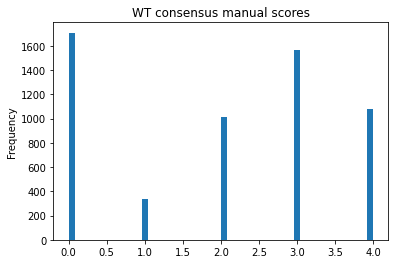

In [481]:
scores_pd = scores.to_pandas()
scores_pd[scores_pd['db_mut_id'] == 0].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores')

In [482]:
# write out results
scores.write_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

## Calculate normalized scores

In [483]:
# prepare data to calculate normalized scores
normalized_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

normalized_scores = normalized_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    (pl.col("adjusted_score").sum() / (len(scoring_conditions)*max_score)).alias("normalized_score")
)

normalized_scores = normalized_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id
i64,i64,i64,str,f64,str
71163,52920,2670,"""VUSAPWT2B1""",0.0,"""2"""
5231,71001,205675,"""VUSAPWT2B1""",0.9375,"""2"""
9746,8416,216644,"""VUSAPWT1B2""",0.0625,"""1"""
100011278,14973,0,"""VUSAPWT1B2""",0.0625,"""1"""
13662,70497,3851,"""VUSAPWT1B1""",0.75,"""1"""
…,…,…,…,…,…
2522,7652,1824,"""VUSAPWT1B1""",0.0,"""1"""
7011,53737,0,"""VUSAPWT2B1""",0.4375,"""2"""
281,281,744,"""VUSAPWT1B1""",0.125,"""1"""


In [484]:
# cast all to same format
normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

normalized_scores = normalized_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
normalized_scores = normalized_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
normalized_scores = normalized_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class
i64,i64,i64,str,f64,str,str,str,f64,f64
71163,52920,2670,"""VUSAPWT2B1""",0.0,"""2""","""1""","""1""",1.0,1.0
5231,71001,205675,"""VUSAPWT2B1""",0.9375,"""2""","""1""","""1""",1.0,1.0
9746,8416,216644,"""VUSAPWT1B2""",0.0625,"""1""","""1""","""1""",1.0,1.0
100011278,14973,0,"""VUSAPWT1B2""",0.0625,"""1""","""1""","""1""",null,null
13662,70497,3851,"""VUSAPWT1B1""",0.75,"""1""","""1""","""1""",1.0,1.0
…,…,…,…,…,…,…,…,…,…
2522,7652,1824,"""VUSAPWT1B1""",0.0,"""1""","""1""","""1""",1.0,1.0
7011,53737,0,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",null,null
281,281,744,"""VUSAPWT1B1""",0.125,"""1""","""1""","""1""",1.0,1.0


In [485]:
dict_after_seq_2 = df_to_dict_variants(normalized_scores)

In [486]:
# # map ad orfs ids to symbol

# horfeome_df = pd.read_csv(f"{meta_inputs}/horfeome_81_91_union.tsv", sep="\t")
# orf_to_symbol_dict = horfeome_df.set_index('orf_id')['symbol'].to_dict()

# # add a key for 0 as empty_AD
# orf_to_symbol_dict[0] = 'empty_AD'

# # update values where orfs are mapped to multiple symbols to only retain one previously used in the lab
# single_symbol_mapping_dict = {
#     1063: 'SMN2',
#     13954: 'AC005833.1',
#     55237: 'NBPF19',
#     2658: 'ZNF559-ZNF177',
#     1940: 'RBMY1F',
#     56585: 'CKMT1A',
#     2794: 'HBA1',
#     978: 'MAGEA2B',
#     70851: 'FAM25G',
#     3824: 'CKMT1A',
#     13813: 'CRYAA',
#     66: 'SMN1',
#     55944: 'KRTAP2-4',
#     13597: 'FAM187A',
#     56508: 'PRR20E',
#     100066377: 'TBC1D3G'
#     }


# for k, v in single_symbol_mapping_dict.items():
#     orf_to_symbol_dict[k] = v


# # apply mapping
# normalized_scores = normalized_scores.with_columns(
#     pl.col("ad_orf_id").replace_strict(orf_to_symbol_dict, default=None).alias("ad_symbol")
# )

In [487]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol
i64,i64,i64,str,f64,str,str,str,f64,f64,str
71163,52920,2670,"""VUSAPWT2B1""",0.0,"""2""","""1""","""1""",1.0,1.0,"""KCNIP1"""
5231,71001,205675,"""VUSAPWT2B1""",0.9375,"""2""","""1""","""1""",1.0,1.0,"""LASP1"""
9746,8416,216644,"""VUSAPWT1B2""",0.0625,"""1""","""1""","""1""",1.0,1.0,"""MTUS2"""
100011278,14973,0,"""VUSAPWT1B2""",0.0625,"""1""","""1""","""1""",null,null,"""KRT16"""
13662,70497,3851,"""VUSAPWT1B1""",0.75,"""1""","""1""","""1""",1.0,1.0,"""CYSRT1"""
…,…,…,…,…,…,…,…,…,…,…
2522,7652,1824,"""VUSAPWT1B1""",0.0,"""1""","""1""","""1""",1.0,1.0,"""TRIM38"""
7011,53737,0,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",null,null,"""CEP63"""
281,281,744,"""VUSAPWT1B1""",0.125,"""1""","""1""","""1""",1.0,1.0,"""MVK"""


In [488]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

normalized_scores = normalized_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,str
71163,52920,2670,"""VUSAPWT2B1""",0.0,"""2""","""1""","""1""",1.0,1.0,"""KCNIP1""","""LITAF""","""Gly130Ser""","""388G>A""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Gly130Ser"""
5231,71001,205675,"""VUSAPWT2B1""",0.9375,"""2""","""1""","""1""",1.0,1.0,"""LASP1""","""UBQLN2""","""Pro506Thr""","""1516C>A""","""ENSG00000188021""","""CEGS2""","""1_Pathogenic""",null,1.0,"""UBQLN2_Pro506Thr"""
9746,8416,216644,"""VUSAPWT1B2""",0.0625,"""1""","""1""","""1""",1.0,1.0,"""MTUS2""","""DCX""","""Arg196Cys""","""586C>T""","""ENSG00000077279""","""CEGS2""","""1_Pathogenic""",null,2.0,"""DCX_Arg196Cys"""
100011278,14973,0,"""VUSAPWT1B2""",0.0625,"""1""","""1""","""1""",null,null,"""KRT16""","""KRT5""",null,null,"""ENSG00000186081""",null,null,null,null,"""KRT5"""
13662,70497,3851,"""VUSAPWT1B1""",0.75,"""1""","""1""","""1""",1.0,1.0,"""CYSRT1""","""AGXT""","""Ser221Pro""","""661T>C""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ser221Pro"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2522,7652,1824,"""VUSAPWT1B1""",0.0,"""1""","""1""","""1""",1.0,1.0,"""TRIM38""","""STXBP1""","""Leu365Phe""","""1093C>T""","""ENSG00000136854""","""Edgotyping3""","""4_VUS""",null,1.0,"""STXBP1_Leu365Phe"""
7011,53737,0,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",null,null,"""CEP63""","""BFSP2""",null,null,"""ENSG00000170819""",null,null,null,null,"""BFSP2"""
281,281,744,"""VUSAPWT1B1""",0.125,"""1""","""1""","""1""",1.0,1.0,"""MVK""","""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp"""


In [489]:
normalized_scores.write_csv(f"{outputs_dir}/4_normalized_consensus_scores.csv")

In [490]:
normalized_scores_manual = normalized_scores

In [491]:
normalized_scores_manual_pd = normalized_scores_manual.to_pandas()
normalized_scores_manual_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,71163,52920,2670,VUSAPWT2B1,0.0000,2,1,1,1.0,1.0,KCNIP1,LITAF,Gly130Ser,388G>A,ENSG00000189067,Edgotyping3,4_VUS,NaN,1.0,LITAF_Gly130Ser
1,5231,71001,205675,VUSAPWT2B1,0.9375,2,1,1,1.0,1.0,LASP1,UBQLN2,Pro506Thr,1516C>A,ENSG00000188021,CEGS2,1_Pathogenic,NaN,1.0,UBQLN2_Pro506Thr
2,9746,8416,216644,VUSAPWT1B2,0.0625,1,1,1,1.0,1.0,MTUS2,DCX,Arg196Cys,586C>T,ENSG00000077279,CEGS2,1_Pathogenic,NaN,2.0,DCX_Arg196Cys
3,100011278,14973,0,VUSAPWT1B2,0.0625,1,1,1,NaN,NaN,KRT16,KRT5,None,None,ENSG00000186081,None,None,NaN,NaN,KRT5
4,13662,70497,3851,VUSAPWT1B1,0.7500,1,1,1,1.0,1.0,CYSRT1,AGXT,Ser221Pro,661T>C,ENSG00000172482,Edgotyping3,1_Pathogenic,NaN,NaN,AGXT_Ser221Pro
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4059,2522,7652,1824,VUSAPWT1B1,0.0000,1,1,1,1.0,1.0,TRIM38,STXBP1,Leu365Phe,1093C>T,ENSG00000136854,Edgotyping3,4_VUS,NaN,1.0,STXBP1_Leu365Phe
4060,7011,53737,0,VUSAPWT2B1,0.4375,2,1,1,NaN,NaN,CEP63,BFSP2,None,None,ENSG00000170819,None,None,NaN,NaN,BFSP2
4061,281,281,744,VUSAPWT1B1,0.1250,1,1,1,1.0,1.0,MVK,MVK,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp
4062,11816,4062,0,VUSAPWT2B1,0.1875,2,1,1,NaN,NaN,TMPRSS2,PLP1,None,None,ENSG00000123560,None,None,NaN,NaN,PLP1


# Exploring qa/qc, dropped alleles

In [492]:
def describe_dict(df_dict):
    for assay_id in df_dict.keys():
        print(f"\tAssay ID: {assay_id}")
        n_db_orfs = len(df_dict[assay_id].keys())
        only_wt_count = 0
        db_list_wt = []
        n_wt = 0
        n_alleles = 0
        db_list_wt_with_var_wt = []
        db_list_wt_with_only_var = []
        ad_list = []
        
        for db_orf_id, db_mut_d in df_dict[assay_id].items():
            # if db_orf_id == 53798:
            #     print('53798')
            #     print(db_mut_d)
            
            if 0 in db_mut_d.keys():
                n_wt += 1
                n_alleles += len(db_mut_d.keys()) - 1
            else:
                n_alleles += len(db_mut_d.keys())
                
            if len(db_mut_d.keys()) == 1 and 0 in db_mut_d.keys():
                only_wt_count += 1
                db_list_wt.append(db_orf_id)
                
            if len(db_mut_d.keys()) > 1 and 0 in db_mut_d.keys():
                db_list_wt_with_var_wt.append(db_orf_id)
                
            if 0 not in db_mut_d.keys():
                db_list_wt_with_only_var.append(db_orf_id)
                
            ad_set = set()
            for db_mut_id, ad_orf_id_set in db_mut_d.items():
                for ad_orf_id in ad_orf_id_set:
                    ad_set.add(ad_orf_id)
                    
            ad_list.extend(list(ad_set))
            
            
        print(f"\t\tNumber of DB ORFs: {n_db_orfs}")        
        print(f"\t\tNumber of DB alleles: {n_alleles}")
        print(f"\t\tNumber of DB ORFs with WT: {n_wt}")
        print(f"\t\tNumber of DB ORFs with only WT: {only_wt_count}, {(only_wt_count/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of DB ORFs with WT and alleles: {len(db_list_wt_with_var_wt)}, {(len(db_list_wt_with_var_wt)/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of DB ORFs with only alleles: {len(db_list_wt_with_only_var)}, {(len(db_list_wt_with_only_var)/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of AD ORFs: {len(ad_list)}")

        print(f"\t\tDB ORFs with only WT: {db_list_wt}")
        print(f"\t\tDB ORFs with WT and alleles: {db_list_wt_with_var_wt}")
        print(f"\t\tDB ORFs with only alleles: {db_list_wt_with_only_var}")
        print()

In [493]:
def compare_dicts(dict1, dict2):
    assay_array = ["VUSAPWT1B1", "VUSAPWT1B2", "VUSAPWT2B1", "VUSAPWT6B1"]
    for assay in assay_array:
        print(f"\tAssay: {assay}")

        lost_alleles = 0
        lost_wt = 0
        lost_db_orfs = 0
        lost_ad_orfs = 0

        total_alleles = 0
        total_wt = 0
        total_db_orfs = 0
        total_ad_orfs = 0

        # Compute totals from dict1
        for db_orf_id, db_mut_id_d in dict1[assay].items():
            total_db_orfs += 1
            if 0 in db_mut_id_d:
                total_wt += 1
                total_alleles += len(db_mut_id_d) - 1  # exclude WT
            else:
                total_alleles += len(db_mut_id_d)
                
            ad_set = set()
                
            ad_set = {ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf}
            total_ad_orfs += len(ad_set)

        for db_orf_id, db_mut_id_d in dict2[assay].items():
            if db_orf_id in dict1[assay]:
                db_mut_id_d1 = dict1[assay][db_orf_id]
                db_mut_id_d2 = db_mut_id_d

                ad_set_1 = {ad for db_mut, ad_orf in db_mut_id_d1.items() for ad in ad_orf}
                ad_set_2 = {ad for db_mut, ad_orf in db_mut_id_d2.items() for ad in ad_orf}
                lost_ad_orfs += len(ad_set_1 - ad_set_2)

                lost_alleles += sum(1 for db_mut in db_mut_id_d1 if db_mut != 0 and db_mut not in db_mut_id_d2)

                if 0 in db_mut_id_d1 and 0 not in db_mut_id_d2:
                    lost_wt += 1

            else:
                lost_db_orfs += 1
                if 0 in db_mut_id_d:
                    lost_wt += 1
                    lost_alleles += len(db_mut_id_d) - 1
                else:
                    lost_alleles += len(db_mut_id_d)

                lost_ad_orfs += len({ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf})

        for db_orf_id, db_mut_id_d in dict1[assay].items():
            if db_orf_id not in dict2[assay]:
                lost_db_orfs += 1
                if 0 in db_mut_id_d:
                    lost_wt += 1
                    lost_alleles += len(db_mut_id_d) - 1
                else:
                    lost_alleles += len(db_mut_id_d)
                lost_ad_orfs += len({ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf})

        def pct(x, total):
            return f"{(x / total * 100):.1f}%" if total else "NA"

        print(f"\t\tLost DB ORFs: {lost_db_orfs} / {total_db_orfs} ({pct(lost_db_orfs, total_db_orfs)})")
        print(f"\t\tLost alleles: {lost_alleles} / {total_alleles} ({pct(lost_alleles, total_alleles)})")
        print(f"\t\tLost WT: {lost_wt} / {total_wt} ({pct(lost_wt, total_wt)})")
        print(f"\t\tLost AD ORFs: {lost_ad_orfs} / {total_ad_orfs} ({pct(lost_ad_orfs, total_ad_orfs)})")
        print()


In [494]:
dicts = [dict_before_qc, dict_after_db_groups, dict_after_db_conditions ,dict_after_mating, dict_after_aa, dict_after_seq_1, dict_after_seq_2]

In [495]:
print("Data filtering through QC/QA:")
print()
print()
print('Before QC:')
print()
describe_dict(dict_before_qc)
print()
print('Step 1: Remove all db groups with the same allele if there was an autoactivation mating failure')
print()
describe_dict(dict_after_db_groups)
print()
print('Differences before QC and step 1:')
print()
compare_dicts(dict_before_qc, dict_after_db_groups)
print()
print('________________________________________________________________________________')
print('Step 2: Remove all db conditions with the same allele if there was an autoactivation mating failure')
print()
describe_dict(dict_after_db_conditions)
print()
print()
print('Differences between step 1 and step 2:')
print()
compare_dicts(dict_after_db_groups, dict_after_db_conditions)
print()
print('________________________________________________________________________________')
print('Step 3: remove mating failures - condition 1 shows no or little yeast growth')
print()
describe_dict(dict_after_mating)
print()
print('Differences between step 2 and step 3:')
print()
compare_dicts(dict_after_db_conditions, dict_after_mating)
print()
print('________________________________________________________________________________')
print('Step 4: Remove autoactivation rows from the main scores df')
print()
describe_dict(dict_after_aa)
print()
print('Differences between step 3 and step 4:')
print()
compare_dicts(dict_after_mating, dict_after_aa)
print()
print('________________________________________________________________________________')
print('Step 5: Filter to only keep interactions where both ad and db are confirmed, before normalizing')
print()
describe_dict(dict_after_seq_1)
print()
print('Differences between step 4 and step 5:')
print()
compare_dicts(dict_after_aa, dict_after_seq_1)
print()
print('________________________________________________________________________________')
print('Step 6: Filter to only keep interactions where both ad and db are confirmed, after normalizing')
print()
describe_dict(dict_after_seq_2)
print()
print('Differences between step 5 and step 6:')
print()
compare_dicts(dict_after_seq_1, dict_after_seq_2)


Data filtering through QC/QA:


Before QC:

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 589
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 251
		Number of DB alleles: 506
		Number of DB ORFs with WT: 251
		Number of DB ORFs with only WT: 107, 42.63%
		Number of DB ORFs with WT and alleles: 144, 57.37%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 910
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2816, 2818, 2866, 3125, 3192, 3292, 35

In [496]:
compare_dicts(dict_before_qc, dict_after_mating)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 0 / 23 (0.0%)
		Lost alleles: 33 / 589 (5.6%)
		Lost WT: 0 / 23 (0.0%)
		Lost AD ORFs: 0 / 104 (0.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 11 / 251 (4.4%)
		Lost alleles: 20 / 506 (4.0%)
		Lost WT: 12 / 251 (4.8%)
		Lost AD ORFs: 47 / 910 (5.2%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 5 / 64 (7.8%)
		Lost alleles: 19 / 275 (6.9%)
		Lost WT: 6 / 64 (9.4%)
		Lost AD ORFs: 35 / 256 (13.7%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 6 / 83 (7.2%)
		Lost alleles: 33 / 361 (9.1%)
		Lost WT: 6 / 83 (7.2%)
		Lost AD ORFs: 39 / 322 (12.1%)



In [497]:
compare_dicts(dict_after_mating, dict_after_aa)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 0 / 23 (0.0%)
		Lost alleles: 21 / 556 (3.8%)
		Lost WT: 0 / 23 (0.0%)
		Lost AD ORFs: 0 / 104 (0.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 1 / 240 (0.4%)
		Lost alleles: 11 / 486 (2.3%)
		Lost WT: 0 / 239 (0.0%)
		Lost AD ORFs: 1 / 863 (0.1%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 2 / 59 (3.4%)
		Lost alleles: 2 / 256 (0.8%)
		Lost WT: 2 / 58 (3.4%)
		Lost AD ORFs: 2 / 221 (0.9%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 0 / 77 (0.0%)
		Lost alleles: 5 / 328 (1.5%)
		Lost WT: 1 / 77 (1.3%)
		Lost AD ORFs: 0 / 283 (0.0%)



In [498]:
compare_dicts(dict_after_aa, dict_after_seq_1)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 2 / 23 (8.7%)
		Lost alleles: 278 / 535 (52.0%)
		Lost WT: 2 / 23 (8.7%)
		Lost AD ORFs: 25 / 104 (24.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 32 / 239 (13.4%)
		Lost alleles: 167 / 475 (35.2%)
		Lost WT: 35 / 239 (14.6%)
		Lost AD ORFs: 159 / 862 (18.4%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 7 / 57 (12.3%)
		Lost alleles: 107 / 254 (42.1%)
		Lost WT: 7 / 56 (12.5%)
		Lost AD ORFs: 46 / 219 (21.0%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 5 / 77 (6.5%)
		Lost alleles: 142 / 323 (44.0%)
		Lost WT: 6 / 76 (7.9%)
		Lost AD ORFs: 16 / 283 (5.7%)



In [499]:
describe_dict(dict_before_qc)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 589
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 251
		Number of DB alleles: 506
		Number of DB ORFs with WT: 251
		Number of DB ORFs with only WT: 107, 42.63%
		Number of DB ORFs with WT and alleles: 144, 57.37%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 910
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2816, 2818, 2866, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878

In [500]:
describe_dict(dict_after_mating)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 556
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 240
		Number of DB alleles: 486
		Number of DB ORFs with WT: 239
		Number of DB ORFs with only WT: 104, 43.33%
		Number of DB ORFs with WT and alleles: 135, 56.25%
		Number of DB ORFs with only alleles: 1, 0.42%
		Number of AD ORFs: 863
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2866, 3108, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878, 4019

In [501]:
describe_dict(dict_after_aa)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 535
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 239
		Number of DB alleles: 475
		Number of DB ORFs with WT: 239
		Number of DB ORFs with only WT: 105, 43.93%
		Number of DB ORFs with WT and alleles: 134, 56.07%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 862
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2866, 3108, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878, 4019

# Automated

In [502]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [503]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = 0
rrs_id = 999999.0

In [504]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [505]:
scores = pd.read_csv(f"{outputs_dir}/2_automated_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control'] == True]
scores = scores[scores['media_control'] == False]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# Fix data types before converting to polars
scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

scores_before_seq = scores.clone()

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,false,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A04""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,544.3046,false,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,false,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A06""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,536.567345,false,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,279.0,null,11451.0,9.99999e5,"""RRS_VUS1_DB_1""","""B01""","""RRS_VUS1_AD_1""","""B01""",4.0,498.666689,false,532.80656,"""CALCOCO2""",null,null,null,null,null,null,null,null,null,"""11451.0_999999.0""","""11451.0_999999.0_LW_VUSAPWT1B1""","""279.0_11451.0_999999.0_VUSAPWT…","""279.0_11451.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P18""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,53212.0,null,54308.0,218853.0,"""VUSMutY8Dh022""","""G09""","""CEGSint_Y8A_7""","""F04""",2.0,412.423535,false,178.228434,"""ROPN1""","""PKP2""","""Ala372Pro""","""1114G>C""","""ENSG00000057294""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""PKP2_Ala372Pro""","""54308.0_218853.0""","""54308.0_218853.0_LWAH1_VUSAPWT…","""53212.0_54308.0_218853.0_VUSAP…","""53212.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218854.0,"""VUSMutY8Dh022""","""H09""","""CEGSint_Y8A_6""","""E11""",2.0,659.198706,false,null,"""SPTA1""","""PKP2""","""Phe424Ser""","""1271T>C""","""ENSG00000057294""","""Edgotyping3""","""4_VUS""",null,2.0,"""PKP2_Phe424Ser""","""54308.0_218854.0""","""54308.0_218854.0_LWAH1_VUSAPWT…","""100069191.0_54308.0_218854.0_V…","""100069191.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_036""","""P20""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00069191e8,null,54308.0,218854.0,"""VUSMu

In [506]:
def get_filtering_stats(scores_df, aa_id, rrs_id, step_name=""):
    """
    Get filtering statistics for a scores dataframe and return as dictionary
    
    Parameters:
    scores_df: polars DataFrame with the scores data
    aa_id: autoactivation ID to exclude 
    rrs_id: RRS ID to exclude
    step_name: optional name for the filtering step
    
    Returns:
    dict: Dictionary containing various counts
    """
    
    # Filter for non-autoactivation, non-RRS entries
    filtered_scores = scores_df.filter(
        (pl.col("ad_orf_id") != aa_id) & 
        (pl.col("db_mut_id") != rrs_id)
    )
    
    stats = {
        'step_name': step_name,
        'total_rows': scores_df.shape[0],
        'ppi_groups': filtered_scores.select(pl.col("ppi_group").n_unique()).item(),
        'db_orf_ids': filtered_scores.select(pl.col("db_orf_id").n_unique()).item(),
        'ad_orf_ids': filtered_scores.select(pl.col("ad_orf_id").n_unique()).item(),
        'db_groups': filtered_scores.select(pl.col("db_group").n_unique()).item(),
        'edge_groups': filtered_scores.select(pl.col("edge_group").n_unique()).item()
    }
    
    # Add counts for db_orf_ids with both WT and variants
    try:
        # Find db_orf_ids with WT data
        db_orfs_with_wt = filtered_scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique()
        
        # Find db_orf_ids with variant data  
        db_orfs_with_variants = filtered_scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique()
        
        # Get intersection - db_orf_ids that have both WT and variants
        db_orfs_with_both = db_orfs_with_wt.join(
            db_orfs_with_variants, 
            on="db_orf_id", 
            how="inner"
        )
        
        stats['db_orfs_with_wt'] = db_orfs_with_wt.height
        stats['db_orfs_with_variants'] = db_orfs_with_variants.height  
        stats['db_orfs_with_both_wt_and_variants'] = db_orfs_with_both.height
        
        # Filter to only include db_orf_ids that have both WT and variants
        scores_both = scores_df.filter(pl.col("db_orf_id").is_in(db_orfs_with_both.select("db_orf_id").to_series().to_list()))
        filtered_scores_both = scores_both.filter(
            (pl.col("ad_orf_id") != aa_id) & 
            (pl.col("db_mut_id") != rrs_id)
        )
        
        # Get ALL the statistics for the WT+variant filtered dataset
        stats['ppi_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ppi_group").n_unique()).item()
        stats['db_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_orf_id").n_unique()).item()
        stats['ad_orf_ids_with_both_wt_variants'] = filtered_scores_both.select(pl.col("ad_orf_id").n_unique()).item()
        stats['db_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("db_group").n_unique()).item()
        stats['edge_groups_with_both_wt_variants'] = filtered_scores_both.select(pl.col("edge_group").n_unique()).item()
        
    except Exception as e:
        print(f"Warning: Could not calculate WT/variant stats for {step_name}: {e}")
        stats['db_orfs_with_wt'] = None
        stats['db_orfs_with_variants'] = None
        stats['db_orfs_with_both_wt_and_variants'] = None
        stats['ppi_groups_with_both_wt_variants'] = None
        stats['db_orf_ids_with_both_wt_variants'] = None
        stats['ad_orf_ids_with_both_wt_variants'] = None
        stats['db_groups_with_both_wt_variants'] = None
        stats['edge_groups_with_both_wt_variants'] = None
    
    return stats

def create_comprehensive_filtering_table(filtering_stats_list):
    """
    Create a comprehensive table showing all filtering steps with counts and percentages
    """
    import pandas as pd
    
    # Initialize the summary table
    summary_data = []
    
    for i, stats in enumerate(filtering_stats_list):
        if i == 0:
            # First step - no previous comparison
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': 0,
                'PPIs_Dropped': 0,
                'DB_ORFs_Dropped': 0,
                'AD_ORFs_Dropped': 0,
                'DB_Groups_Dropped': 0,
                'Edge_Groups_Dropped': 0,
                'DB_ORFs_Both_Dropped': 0,
                'PPI_Groups_Both_Dropped': 0,
                'DB_ORF_IDs_Both_Dropped': 0,
                'AD_ORF_IDs_Both_Dropped': 0,
                'DB_Groups_Both_Dropped': 0,
                'Edge_Groups_Both_Dropped': 0,
                'Percent_Rows_Dropped': 0.0,
                'Percent_PPIs_Dropped': 0.0,
                'Percent_DB_ORFs_Dropped': 0.0,
                'Percent_AD_ORFs_Dropped': 0.0,
                'Percent_DB_Groups_Dropped': 0.0,
                'Percent_Edge_Groups_Dropped': 0.0,
                'Percent_DB_ORFs_Both_Dropped': 0.0,
                'Percent_PPI_Groups_Both_Dropped': 0.0,
                'Percent_DB_ORF_IDs_Both_Dropped': 0.0,
                'Percent_AD_ORF_IDs_Both_Dropped': 0.0,
                'Percent_DB_Groups_Both_Dropped': 0.0,
                'Percent_Edge_Groups_Both_Dropped': 0.0
            }
        else:
            # Compare with previous step
            prev_stats = filtering_stats_list[i-1]
            
            rows_dropped = prev_stats['total_rows'] - stats['total_rows']
            ppis_dropped = prev_stats['ppi_groups'] - stats['ppi_groups']
            db_orfs_dropped = prev_stats['db_orf_ids'] - stats['db_orf_ids']
            ad_orfs_dropped = prev_stats['ad_orf_ids'] - stats['ad_orf_ids']
            db_groups_dropped = prev_stats['db_groups'] - stats['db_groups']
            edge_groups_dropped = prev_stats['edge_groups'] - stats['edge_groups']
            
            # Handle WT/variant specific drops for ALL metrics
            db_orfs_both_dropped = 0
            ppi_groups_both_dropped = 0
            db_orf_ids_both_dropped = 0
            ad_orf_ids_both_dropped = 0
            db_groups_both_dropped = 0
            edge_groups_both_dropped = 0
            
            if (prev_stats.get('db_orfs_with_both_wt_and_variants') is not None and 
                stats.get('db_orfs_with_both_wt_and_variants') is not None):
                db_orfs_both_dropped = prev_stats['db_orfs_with_both_wt_and_variants'] - stats['db_orfs_with_both_wt_and_variants']
                ppi_groups_both_dropped = prev_stats['ppi_groups_with_both_wt_variants'] - stats['ppi_groups_with_both_wt_variants']
                db_orf_ids_both_dropped = prev_stats['db_orf_ids_with_both_wt_variants'] - stats['db_orf_ids_with_both_wt_variants']
                ad_orf_ids_both_dropped = prev_stats['ad_orf_ids_with_both_wt_variants'] - stats['ad_orf_ids_with_both_wt_variants']
                db_groups_both_dropped = prev_stats['db_groups_with_both_wt_variants'] - stats['db_groups_with_both_wt_variants']
                edge_groups_both_dropped = prev_stats['edge_groups_with_both_wt_variants'] - stats['edge_groups_with_both_wt_variants']
            
            row = {
                'Step': stats['step_name'],
                'Total_Rows': stats['total_rows'],
                'PPI_Groups': stats['ppi_groups'],
                'DB_ORF_IDs': stats['db_orf_ids'],
                'AD_ORF_IDs': stats['ad_orf_ids'],
                'DB_Groups': stats['db_groups'],
                'Edge_Groups': stats['edge_groups'],
                'DB_ORFs_Both_WT_Variants': stats.get('db_orfs_with_both_wt_and_variants', 'N/A'),
                'PPI_Groups_Both': stats.get('ppi_groups_with_both_wt_variants', 'N/A'),
                'DB_ORF_IDs_Both': stats.get('db_orf_ids_with_both_wt_variants', 'N/A'),
                'AD_ORF_IDs_Both': stats.get('ad_orf_ids_with_both_wt_variants', 'N/A'),
                'DB_Groups_Both': stats.get('db_groups_with_both_wt_variants', 'N/A'),
                'Edge_Groups_Both': stats.get('edge_groups_with_both_wt_variants', 'N/A'),
                'Rows_Dropped': rows_dropped,
                'PPIs_Dropped': ppis_dropped,
                'DB_ORFs_Dropped': db_orfs_dropped,
                'AD_ORFs_Dropped': ad_orfs_dropped,
                'DB_Groups_Dropped': db_groups_dropped,
                'Edge_Groups_Dropped': edge_groups_dropped,
                'DB_ORFs_Both_Dropped': db_orfs_both_dropped,
                'PPI_Groups_Both_Dropped': ppi_groups_both_dropped,
                'DB_ORF_IDs_Both_Dropped': db_orf_ids_both_dropped,
                'AD_ORF_IDs_Both_Dropped': ad_orf_ids_both_dropped,
                'DB_Groups_Both_Dropped': db_groups_both_dropped,
                'Edge_Groups_Both_Dropped': edge_groups_both_dropped,
                'Percent_Rows_Dropped': round((rows_dropped / prev_stats['total_rows']) * 100, 2) if prev_stats['total_rows'] > 0 else 0,
                'Percent_PPIs_Dropped': round((ppis_dropped / prev_stats['ppi_groups']) * 100, 2) if prev_stats['ppi_groups'] > 0 else 0,
                'Percent_DB_ORFs_Dropped': round((db_orfs_dropped / prev_stats['db_orf_ids']) * 100, 2) if prev_stats['db_orf_ids'] > 0 else 0,
                'Percent_AD_ORFs_Dropped': round((ad_orfs_dropped / prev_stats['ad_orf_ids']) * 100, 2) if prev_stats['ad_orf_ids'] > 0 else 0,
                'Percent_DB_Groups_Dropped': round((db_groups_dropped / prev_stats['db_groups']) * 100, 2) if prev_stats['db_groups'] > 0 else 0,
                'Percent_Edge_Groups_Dropped': round((edge_groups_dropped / prev_stats['edge_groups']) * 100, 2) if prev_stats['edge_groups'] > 0 else 0,
                'Percent_DB_ORFs_Both_Dropped': round((db_orfs_both_dropped / prev_stats['db_orfs_with_both_wt_and_variants']) * 100, 2) if prev_stats.get('db_orfs_with_both_wt_and_variants', 0) > 0 else 0,
                'Percent_PPI_Groups_Both_Dropped': round((ppi_groups_both_dropped / prev_stats['ppi_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('ppi_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_ORF_IDs_Both_Dropped': round((db_orf_ids_both_dropped / prev_stats['db_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_AD_ORF_IDs_Both_Dropped': round((ad_orf_ids_both_dropped / prev_stats['ad_orf_ids_with_both_wt_variants']) * 100, 2) if prev_stats.get('ad_orf_ids_with_both_wt_variants', 0) > 0 else 0,
                'Percent_DB_Groups_Both_Dropped': round((db_groups_both_dropped / prev_stats['db_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('db_groups_with_both_wt_variants', 0) > 0 else 0,
                'Percent_Edge_Groups_Both_Dropped': round((edge_groups_both_dropped / prev_stats['edge_groups_with_both_wt_variants']) * 100, 2) if prev_stats.get('edge_groups_with_both_wt_variants', 0) > 0 else 0
            }
        
        summary_data.append(row)
    
    # Create DataFrame
    df = pd.DataFrame(summary_data)
    
    return df

In [507]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])
# print(db_seq)

## Add an extra QC step to check the sequence confirmation results
seq_confirm_res_df = pd.read_table(f"{meta_inputs}/seq_confirmation_results/VarChampSeqConfirmationResult.tsv")
# with pd.option_context('display.max_columns', None):
#     display(seq_confirm_res_df)

db_seq = pl.DataFrame(
    pd.merge(db_seq.to_pandas(), 
            seq_confirm_res_df[
                ["orf_id_wt","mutation_id_old","db_sequenced","db_sequence_confirmation_class", 'entry_sequence_confirmation_class', 'n2h_sequence_confirmation_class', 'dualip_sequence_confirmation_class', 'mislocalization_sequence_confirmation_class'] ##"symbol","aa_change","nt_change","ccsb_mutation_id"
            ].rename({"orf_id_wt": "db_orf_id",
                      "mutation_id_old": "db_mut_id"}, axis=1), 
        on=["db_orf_id","db_mut_id"],
        how="left"
    )
)
print(db_seq)
# print(db_seq["db_sequenced"].unique())
# print(db_seq.filter(pl.col("db_sequenced")==0))
# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

# print(scores.filter(pl.col("db_mut_id")==0))

## Filter to only keep interactions where both ad and db are confirmed
## And also confirmed by the sequence confirmation results
valid_db_sequence_confirmation_class = [1., 2., 7., 99.]

scores_aa = scores.filter(pl.col("ad_orf_id") == aa_id)

# Old logic
# stop
# scores = scores.filter(
#     (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & (((pl.col("db_sequence_confirmation_class").is_in(valid_db_sequence_confirmation_class)) & (pl.col("db_sequenced").is_not_null())) | (pl.col("db_mut_id")==0))
# )

sequence_confirmation_class_valid = [1., 2.]
sequence_confirmation_class_to_check = [7., 99.]

scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") # SWIM-seq confirmed ad and db
    & 
    (
        (pl.col("db_mut_id")==0)  # WT is always good
        | 
        (
            (pl.col("db_sequence_confirmation_class").is_in(sequence_confirmation_class_valid)) 
            & 
            (pl.col("db_sequenced").is_not_null())
        )  # db_sequence_confirmation_class is 1 or 2: GOOD
        |
        (
            (pl.col("db_sequence_confirmation_class").is_in(sequence_confirmation_class_to_check))  # db is 7 or 99: check entry_clone
            |
            (pl.col("db_sequenced").is_null()) 
            & 
            (
                (pl.col("entry_sequence_confirmation_class").is_in(sequence_confirmation_class_valid))  # entry is 1 or 2: GOOD
                |
                (
                    (pl.col("entry_sequence_confirmation_class").is_in(sequence_confirmation_class_to_check))  # entry is 7 or 99: check other assays
                    &
                    (
                        (pl.col("n2h_sequence_confirmation_class").is_in(sequence_confirmation_class_valid))
                        |
                        (pl.col("dualip_sequence_confirmation_class").is_in(sequence_confirmation_class_valid))
                        |
                        (pl.col("mislocalization_sequence_confirmation_class").is_in(sequence_confirmation_class_valid))
                    )  # At least one of the 3 other assays is 1 or 2: GOOD
                )
            )
        )
    )
)


# add back empty AD (scores_aa) on the scores df
# Add missing columns to scores_aa and fill with None
for col in ["seq_ad", "seq_db", "db_sequenced", "db_sequence_confirmation_class", 'entry_sequence_confirmation_class', 'n2h_sequence_confirmation_class', 'dualip_sequence_confirmation_class', 'mislocalization_sequence_confirmation_class']:
    if col not in scores_aa.columns:
        scores_aa = scores_aa.with_columns(pl.lit(None).alias(col))

# Ensure column types match before concatenation
for col, dtype in zip(scores.schema.keys(), scores.schema.values()):
    if col in scores_aa.columns and scores_aa.schema[col] != dtype:
        scores_aa = scores_aa.with_columns(pl.col(col).cast(dtype))

scores = pl.concat([scores, scores_aa])


## After sequence confirmation, we lost 25521 - 21895 = 3626 interactions
# print(scores.shape)
print(scores)

# Numbers of interactions before filtering



# scores_pd = scores.to_pandas()

# count_after = scores_pd[
#     (scores_pd['ad_orf_id'] != aa_id) &
#     (scores_pd['db_mut_id'] != rrs_id)
#     ].ppi_group.nunique()

# node_count_after = scores_pd[
#     (scores_pd['ad_orf_id'] != aa_id) &
#     (scores_pd['db_mut_id'] != rrs_id)
#     ].db_orf_id.nunique()

# ad_count_after = scores_pd[
#     (scores_pd['ad_orf_id'] != aa_id) &
#     (scores_pd['db_mut_id'] != rrs_id)
#     ].ad_orf_id.nunique()

# print(f"Number of interactions after filtering: {count_after}")
# print(f"Number of nodes after filtering: {node_count_after}")
# print(f"Number of AD nodes after filtering: {ad_count_after}")

# print('difference =', count_before - count_after)
# print('difference in nodes =', node_count - node_count_after)
# print('difference in AD nodes =', ad_count - ad_count_after)

scores_after_seq = scores.clone()

shape: (2_887, 9)
┌───────────┬───────────┬────────┬────────────┬───┬────────────┬───────────┬───────────┬───────────┐
│ db_orf_id ┆ db_mut_id ┆ seq_db ┆ db_sequenc ┆ … ┆ entry_sequ ┆ n2h_seque ┆ dualip_se ┆ mislocali │
│ ---       ┆ ---       ┆ ---    ┆ ed         ┆   ┆ ence_confi ┆ nce_confi ┆ quence_co ┆ zation_se │
│ i64       ┆ i64       ┆ str    ┆ ---        ┆   ┆ rmation_cl ┆ rmation_c ┆ nfirmatio ┆ quence_co │
│           ┆           ┆        ┆ f64        ┆   ┆ …          ┆ las…      ┆ n_c…      ┆ nfi…      │
│           ┆           ┆        ┆            ┆   ┆ ---        ┆ ---       ┆ ---       ┆ ---       │
│           ┆           ┆        ┆            ┆   ┆ f64        ┆ f64       ┆ f64       ┆ f64       │
╞═══════════╪═══════════╪════════╪════════════╪═══╪════════════╪═══════════╪═══════════╪═══════════╡
│ 281       ┆ 727       ┆ NULL   ┆ 1.0        ┆ … ┆ 2.0        ┆ 99.0      ┆ 5.0       ┆ 1.0       │
│ 281       ┆ 739       ┆ 1      ┆ 1.0        ┆ … ┆ 1.0        ┆ null    

In [508]:
scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,entry_sequence_confirmation_class,n2h_sequence_confirmation_class,dualip_sequence_confirmation_class,mislocalization_sequence_confirmation_class
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,false,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,null,null,null,null,null
"""VUSAPWT1B1r01_001""","""A16""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,595.377806,false,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,null,null,null,null,null
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,false,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,null,null,null,null,null
"""VUSAPWT1B1r01_001""","""A18""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,603.194803,false,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,null,null,null,null,null
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,false,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P06""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,0,null,13295,218058,"""VUSMutY8Dh022""","""H03""","""CEGSint_Y8A1_2_6""","""D01""",0.0,0.0,false,1.149346,"""empty_ad""","""TTPA""","""His101Gln""","""303T>G""","""ENSG00000137561""","""CEGS2""","""1_Pathogenic""",null,2.0,"""TTPA_His101Gln""","""13295.0_218058.0""","""13295.0_218058.0_LWAH1_VUSAPWT…","""0.0_13295.0_218058.0_VUSAPWT1B…","""0.0_13295.0_VUSAPWT1B1""",null,"""0""",1.0,1.0,1.0,1.0,5.0,1.0
"""VUSAPWT1B1r06_036""","""P09""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,0,null,2595,999999,"""

In [509]:
scores_pd = scores.to_pandas()
scores_pd

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,entry_sequence_confirmation_class,n2h_sequence_confirmation_class,dualip_sequence_confirmation_class,mislocalization_sequence_confirmation_class
0,VUSAPWT1B1r01_001,A15,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,4.0,528.001331,False,558.350679,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,NaN,NaN,NaN,NaN,NaN,NaN
1,VUSAPWT1B1r01_001,A16,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,71704,NaN,11805,0,DisWTGDEh03,C04,CEGSint_Y8A_1,C01,4.0,595.377806,False,558.350679,SMURF2,SMAD3,None,None,ENSG00000166949,None,None,NaN,NaN,SMAD3,11805.0_0.0,11805.0_0.0_LW_VUSAPWT1B1,71704.0_11805.0_0.0_VUSAPWT1B1,71704.0_11805.0_VUSAPWT1B1,1,1,NaN,NaN,NaN,NaN,NaN,NaN
2,VUSAPWT1B1r01_001,A17,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,4.0,585.556892,False,586.988591,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,NaN,NaN,NaN,NaN,NaN,NaN
3,VUSAPWT1B1r01_001,A18,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,13662,NaN,70497,0,DisWTGDEh03,D04,CEGSint_Y8A_5,H07,4.0,603.194803,False,586.988591,CYSRT1,AGXT,None,None,ENSG00000172482,None,None,NaN,NaN,AGXT,70497.0_0.0,70497.0_0.0_LW_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,NaN,NaN,NaN,NaN,NaN,NaN
4,VUSAPWT1B1r01_001,A23,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,11567,NaN,52920,0,DisWTGDEh03,A05,CEGSint_Y8A_5,A06,4.0,572.135977,False,578.211793,TAX1BP1,LITAF,None,None,ENSG00000189067,None,None,NaN,NaN,LITAF,52920.0_0.0,52920.0_0.0_LW_VUSAPWT1B1,11567.0_52920.0_0.0_VUSAPWT1B1,11567.0_52920.0_VUSAPWT1B1,1,1,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175519,VUSAPWT1B1r06_036,P06,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,13295,218058,VUSMutY8Dh022,H03,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,1.149346,empty_ad,TTPA,His101Gln,303T>G,ENSG00000137561,CEGS2,1_Pathogenic,NaN,2.0,TTPA_His101Gln,13295.0_218058.0,13295.0_218058.0_LWAH1_VUSAPWT1B1,0.0_13295.0_218058.0_VUSAPWT1B1,0.0_13295.0_VUSAPWT1B1,None,0,1.0,1.0,1.0,1.0,5.0,1.0
175520,VUSAPWT1B1r06_036,P09,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,2595,999999,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,0.000000,empty_ad,None,None,None,None,None,None,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,NaN,NaN,NaN,NaN,NaN,NaN
175521,VUSAPWT1B1r06_036,P10,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,2595,999999,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,0.000000,empty_ad,None,None,None,None,None,None,NaN,NaN,None,2595.0_999999.0,2595.0_999999.0_LWAH1_VUSAPWT1B1,0.0_2595.0_999999.0_VUSAPWT1B1,0.0_2595.0_VUSAPWT1B1,None,None,NaN,NaN,NaN,NaN,NaN,NaN
175522,VUSAPWT1B1r06_036,P11,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,7167,999999,RRS_VUS1_DB_2,H05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,117.067323,empty_ad,None,None,None,None,None,None,NaN,NaN,Non

In [510]:
scores_pd[
    (scores_pd['db_orf_id'] == 71892) &
    (scores_pd['db_mut_id'] == 4008) 
]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,entry_sequence_confirmation_class,n2h_sequence_confirmation_class,dualip_sequence_confirmation_class,mislocalization_sequence_confirmation_class
1668,VUSAPWT1B1r01_030,K13,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1,False,71892,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A_1,E08,4.0,599.915058,False,566.01277,TH,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LW_VUSAPWT1B1,71892.0_71892.0_4008.0_VUSAPWT1B1,71892.0_71892.0_VUSAPWT1B1,1,1,1.0,1.0,3.0,1.0,3.0,3.0
1669,VUSAPWT1B1r01_030,K14,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1,False,71892,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A_1,E08,4.0,543.419632,False,566.01277,TH,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LW_VUSAPWT1B1,71892.0_71892.0_4008.0_VUSAPWT1B1,71892.0_71892.0_VUSAPWT1B1,1,1,1.0,1.0,3.0,1.0,3.0,3.0
1678,VUSAPWT1B1r01_030,L13,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1,False,71892,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A_1,E08,4.0,532.407869,False,566.01277,TH,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LW_VUSAPWT1B1,71892.0_71892.0_4008.0_VUSAPWT1B1,71892.0_71892.0_VUSAPWT1B1,1,1,1.0,1.0,3.0,1.0,3.0,3.0
1679,VUSAPWT1B1r01_030,L14,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1,False,71892,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A_1,E08,4.0,588.308522,False,566.01277,TH,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LW_VUSAPWT1B1,71892.0_71892.0_4008.0_VUSAPWT1B1,71892.0_71892.0_VUSAPWT1B1,1,1,1.0,1.0,3.0,1.0,3.0,3.0
1690,VUSAPWT1B1r01_030,M13,VUSAPWT1B1r01_025_026_027_028_029_030,VUSAPWT1B1,r07,LW,1,False,5441,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A_5,B07,4.0,620.905910,False,598.09872,PUF60,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LW_VUSAPWT1B1,5441.0_71892.0_4008.0_VUSAPWT1B1,5441.0_71892.0_VUSAPWT1B1,1,1,1.0,1.0,3.0,1.0,3.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117846,VUSAPWT1B1r05_030,J14,VUSAPWT1B1r05_025_026_027_028_029_030,VUSAPWT1B1,r11,LWH25,1,False,0,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A1_2_6,C01,0.0,117.724185,False,143.69510,empty_ad,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LWH25_VUSAPWT1B1,0.0_71892.0_4008.0_VUSAPWT1B1,0.0_71892.0_VUSAPWT1B1,None,1,1.0,1.0,3.0,1.0,3.0,3.0
119505,VUSAPWT1B1r06_030,I13,VUSAPWT1B1r06_025_026_027_028_029_030,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A1_2_6,C01,0.0,0.000000,False,0.00000,empty_ad,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LWAH1_VUSAPWT1B1,0.0_71892.0_4008.0_VUSAPWT1B1,0.0_71892.0_VUSAPWT1B1,None,1,1.0,1.0,3.0,1.0,3.0,3.0
119506,VUSAPWT1B1r06_030,I14,VUSAPWT1B1r06_025_026_027_028_029_030,VUSAPWT1B1,r12,LWAH1,1,False,0,NaN,71892,4008,VUSMutY8Dh015,D10,CEGSint_Y8A1_2_6,C01,0.0,0.000000,False,0.00000,empty_ad,TH,Glu250Gln,748G>C,ENSG00000180176,Edgotyping3,4_VUS,NaN,1.0,TH_Glu250Gln,71892.0_4008.0,71892.0_4008.0_LWAH1_VUSAPWT1B1,0.0_71892.0_4008.0_VUSAPWT1B1,0.0_71892.0_VUSAPWT1B1,None,1,1.0,1.0,3.0,1.0,3.0,3.0
119521,VUSAPWT1B1r06_030,J13,VUSAPW

In [ ]:
seq_confirm_res_df[
    (seq_confirm_res_df['orf_id_wt'] == 71892) &
    (seq_confirm_res_df['mutation_id_old'] == 4008)
]

,symbol,ensembl_gene_id,orf_id_wt,mutation_id_old,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,dualip_ref_sequence_confirmation_class,mislocalization_sequenced,mislocalization_sequence_confirmation_class,mislocalization_ref_sequence_confirmation_class
8384,TH,ENSG00000180176,71892,4008,CCSBVarC008288,ALE00008274,NC_000011.10:2166980:C:G,748G>C,Glu250Gln,Edgotyping3,VUSMutGDEh015,D10,GDEhDisVCh_40019,C10,1.0,VUSMutGDDh015,D10,VUSN2Hmut_GDN2h_04,F11,VUSMutpDEST2_15,B08,VUSmut_GDEh04,F11,1,3.0,1,1.0,1,1.0,1.0,1,3.0,1.0,1,3.0,1.0


In [ ]:
db_seq_pd = db_seq.to_pandas()
db_seq_pd[
    (db_seq_pd['db_orf_id'] == 71892) &
    (db_seq_pd['db_mut_id'] == 4008)
]

,db_orf_id,db_mut_id,seq_db,db_sequenced,db_sequence_confirmation_class,entry_sequence_confirmation_class,n2h_sequence_confirmation_class,dualip_sequence_confirmation_class,mislocalization_sequence_confirmation_class
1323,71892,4008,1,1.0,1.0,3.0,1.0,3.0,3.0


In [ ]:
db_seq_pd

,db_orf_id,db_mut_id,seq_db,db_sequenced,db_sequence_confirmation_class,entry_sequence_confirmation_class,n2h_sequence_confirmation_class,dualip_sequence_confirmation_class,mislocalization_sequence_confirmation_class


In [ ]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class
20136,VUSAPWT1B2r01_035,G15,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,4.0,NaN,False,NaN,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LW_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
20137,VUSAPWT1B2r01_035,G16,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,4.0,NaN,False,NaN,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LW_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
20166,VUSAPWT1B2r01_035,H15,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,4.0,410.532033,False,NaN,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LW_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
20167,VUSAPWT1B2r01_035,H16,VUSAPWT1B2r01_031_032_033_034_035_036,VUSAPWT1B2,r07,LW,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,4.0,469.305896,False,NaN,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LW_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
26472,VUSAPWT1B2r02_035,G15,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,0.0,0.000000,False,166.396409,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LWA_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
26473,VUSAPWT1B2r02_035,G16,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,0.0,518.027463,False,166.396409,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LWA_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
26502,VUSAPWT1B2r02_035,H15,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,0.0,0.000000,False,166.396409,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LWA_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
26503,VUSAPWT1B2r02_035,H16,VUSAPWT1B2r02_031_032_033_034_035_036,VUSAPWT1B2,r08,LWA,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,0.0,147.558173,False,166.396409,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LWA_VUSAPWT1B2,100000407.0_2803.0_200947.0_VUSAPWT1B2,100000407.0_2803.0_VUSAPWT1B2,1,1,1.0,2.0
32808,VUSAPWT1B2r03_035,G15,VUSAPWT1B2r03_031_032_033_034_035_036,VUSAPWT1B2,r09,LWH1,1,False,100000407,NaN,2803,200947,VUSMutY8Dh031,G10,CEGSint_Y8A_3,E04,3.0,525.771264,False,537.289239,PICK1,HMBS,Asp359Asn,1075G>A,ENSG00000256269,CEGS2,2_Benign,0.000065,2.0,HMBS_Asp359Asn,2803.0_200947.0,2803.0_200947.0_LWH1_VUSAP

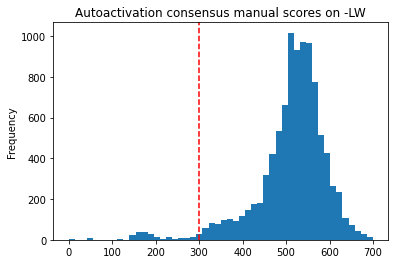

In [ ]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd.ad_orf_id == aa_id) &
    (scores_pd.condition_name == 'LW')
].consensus_score.plot(kind='hist', bins=50, title='Autoactivation consensus manual scores on -LW')
plt.axvline(x=300, color='red', linestyle='--', label='Threshold')

In [ ]:
# print('Before filtering:')
# print(scores.shape)
# print('ppi_group', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ppi_group").n_unique()).item())
# print('db_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_orf_id").n_unique()).item())
# print('ad_orf_ids', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("ad_orf_id").n_unique()).item())
# print('db_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("db_group").n_unique()).item())
# print('edge_groups', scores.filter(
#     (pl.col("ad_orf_id") != aa_id) & 
#     (pl.col("db_mut_id") != rrs_id)
# ).select(pl.col("edge_group").n_unique()).item())



# Usage example - replace your current print statements with:
# stats_before = get_filtering_stats(scores, aa_id, rrs_id, "Before filtering")
# print_filtering_stats(stats_before)

# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print('After aa mating failure LW:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print('After aa mating failure other media:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))


print('After mating failure LW step 1:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# Takes care of cases of mating failures where the consensus score is null
mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

print('After mating failure LW step 2:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
)

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

print('remove aa rows:?')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


# substract aa values or
# remove if aa value > x (300)?

scores_adjusted = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
   ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print('after adjusted score:')
print(scores_adjusted.shape)
print('ppis', scores_adjusted.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

# alternative approach, remove rows where aa score is greater than 300
scores_300 = scores.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))

print('after aa > 300:')
print(scores_300.shape)
print('ppis', scores_300.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())

scores_pd = scores.to_pandas()

print(len(scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]))


scores = scores_300
scores

After aa mating failure LW:
(167557, 38)
ppis 4375
nodes 244
ads 777
48
After aa mating failure other media:
(167557, 38)
ppis 4375
nodes 244
ads 777
48
After mating failure LW step 1:
(162229, 38)
ppis 4153
nodes 244
ads 757
48
After mating failure LW step 2:
(142880, 38)
ppis 3650
nodes 232
ads 695
0
remove aa rows:?
(87599, 39)
ppis 3650
nodes 232
ads 695
0
after adjusted score:
(55033, 40)
ppis 3265
nodes 232
ads 695
after aa > 300:
(72955, 39)
ppis 3638
nodes 232
ads 695
0


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,f64
"""VUSAPWT1B1r01_016""","""A01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,631.349047,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""A02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,597.499373,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""B01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,559.39349,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""B02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,523.231397,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""E01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_5""","""A06""",4.0,635.023557,false,584.419307,"""TAX1BP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""11567.0_52920.0_2678.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P16""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,3598,null,52920,218637,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_6""","""B02""",2.0,null,false,null,"""DAZAP2""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""3598.0_52920.0_218637.0_VUSAPW…","""3598.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,0.0
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1"

In [ ]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,aa_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,f64
"""VUSAPWT1B1r01_016""","""A01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,631.349047,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""A02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,597.499373,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""B01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,559.39349,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""B02""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,56215,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_4""","""F03""",4.0,523.231397,false,577.868327,"""HIP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""56215.0_52920.0_2678.0_VUSAPWT…","""56215.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
"""VUSAPWT1B1r01_016""","""E01""","""VUSAPWT1B1r01_013_014_015_016_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,2678,"""VUSMutY8Dh007""","""A01""","""CEGSint_Y8A_5""","""A06""",4.0,635.023557,false,584.419307,"""TAX1BP1""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""52920.0_2678.0""","""52920.0_2678.0_LW_VUSAPWT1B1""","""11567.0_52920.0_2678.0_VUSAPWT…","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P16""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,3598,null,52920,218637,"""VUSMutY8Dh022""","""F07""","""CEGSint_Y8A_6""","""B02""",2.0,null,false,null,"""DAZAP2""","""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""","""52920.0_218637.0""","""52920.0_218637.0_LWAH1_VUSAPWT…","""3598.0_52920.0_218637.0_VUSAPW…","""3598.0_52920.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,0.0
"""VUSAPWT1B1r06_036""","""P19""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1"

In [ ]:
scores_pd = scores.to_pandas()
values = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].dropna(subset=['consensus_score']).consensus_score.tolist()

# find 5% lower values
lower_bound = np.percentile(values, 5)
print(f"Lower bound for LWH1 WT: {lower_bound}")

Lower bound for LWH1 WT: 128.98464242368937


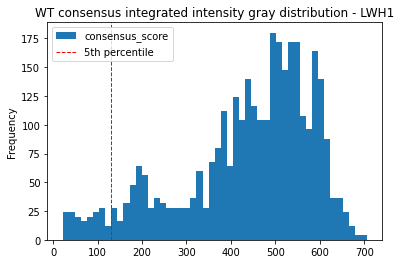

In [ ]:
scores_pd = scores.to_pandas()
fig = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].consensus_score.plot(kind='hist', bins=50, title='WT consensus integrated intensity gray distribution - LWH1')

plt.axvline(lower_bound, color='red', linestyle='dashed', linewidth=1, label='5th percentile')
plt.legend()

In [ ]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                            .filter(pl.col("db_mut_id") == 0)
                            .filter(pl.col("consensus_score") <= lower_bound)
                            .select('edge_group')
                            .to_series().unique().to_list())
scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

print('removing WT failures:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


wt_failures

removing WT failures:
(69088, 39)
ppis 3443
nodes 222
ads 679


['56717.0_53065.0_VUSAPWT1B2',
 '3958.0_3980.0_VUSAPWT2B1',
 '100069021.0_5431.0_VUSAPWT2B1',
 '8359.0_3980.0_VUSAPWT2B1',
 '3148.0_71191.0_VUSAPWT6B1',
 '56446.0_3535.0_VUSAPWT6B1',
 '100069030.0_3693.0_VUSAPWT2B1',
 '56717.0_4765.0_VUSAPWT1B1',
 '13662.0_11895.0_VUSAPWT1B2',
 '71963.0_71258.0_VUSAPWT6B1',
 '7408.0_6408.0_VUSAPWT6B1',
 '9746.0_8416.0_VUSAPWT1B2',
 '5285.0_56661.0_VUSAPWT1B1',
 '824.0_9818.0_VUSAPWT1B2',
 '3958.0_2448.0_VUSAPWT2B1',
 '11830.0_7675.0_VUSAPWT2B1',
 '55647.0_12132.0_VUSAPWT1B2',
 '3818.0_5712.0_VUSAPWT2B1',
 '3102.0_10343.0_VUSAPWT6B1',
 '6965.0_71191.0_VUSAPWT2B1',
 '81261.0_7147.0_VUSAPWT6B1',
 '6534.0_54847.0_VUSAPWT1B2',
 '824.0_56661.0_VUSAPWT1B1',
 '100015297.0_13554.0_VUSAPWT6B1',
 '13795.0_8416.0_VUSAPWT1B2',
 '6759.0_52920.0_VUSAPWT2B1',
 '11621.0_5673.0_VUSAPWT6B1',
 '11423.0_53030.0_VUSAPWT6B1',
 '11452.0_5712.0_VUSAPWT6B1',
 '10844.0_7198.0_VUSAPWT6B1',
 '100080816.0_4062.0_VUSAPWT6B1',
 '13600.0_70497.0_VUSAPWT1B1',
 '54957.0_53737.0_VUSAPWT1

In [ ]:
scores_pd = scores.to_pandas()

scores_pd[
    (scores_pd['db_orf_id'] == 2803) & 
    (scores_pd['db_mut_id'] == 200947) 
    ]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,aa_score


In [ ]:
# write out results
scores.write_csv(f"{outputs_dir}/3_automated_qaqc_consensus_scores.csv")

In [ ]:
# Summing scores

# Keep a reference to original data with condition names
original_conditions = scores.filter(pl.col("condition_name").is_in(scoring_conditions)).select([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch', 'condition_name'
]).unique()

summed_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# First, sum adjusted scores across conditions for each variant
summed_scores = summed_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

# Get WT scores (db_mut_id == 0) for normalization
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join variant scores with their corresponding WT scores
summed_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
)
# .select([
#     "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", 
#     "summed_consensus_score", "wt_summed_score", 'condition_name'
# ])

# Join back with original to get condition names
summed_scores = summed_scores.join(
    original_conditions,
    on=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"],
    how="left"
)

summed_scores_pd = summed_scores.to_pandas()
print(summed_scores_pd.db_orf_id.nunique())

summed_scores = summed_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

summed_scores = summed_scores.with_columns(
    pl.concat_str([
        pl.col('ad_orf_id').cast(pl.String),
        pl.col('db_orf_id').cast(pl.String),
        pl.col('db_mut_id').cast(pl.String),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

summed_scores

222
222
213


ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group
i64,i64,i64,str,f64,f64,str,str,str
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWA""","""6""","""100080183_71191_205705_VUSAPWT…"
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH1""","""6""","""100080183_71191_205705_VUSAPWT…"
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH25""","""6""","""100080183_71191_205705_VUSAPWT…"
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH10""","""6""","""100080183_71191_205705_VUSAPWT…"
8186,4062,201426,"""VUSAPWT2B1""",1079.230965,4267.784888,"""LWH1""","""2""","""8186_4062_201426_VUSAPWT2B1"""
…,…,…,…,…,…,…,…,…
252,1668,214082,"""VUSAPWT1B2""",1435.732045,1228.28237,"""LWA""","""1""","""252_1668_214082_VUSAPWT1B2"""
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWH1""","""1""","""100009072_70368_205543_VUSAPWT…"
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWA""","""1""","""100009072_70368_205543_VUSAPWT…"


In [ ]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


(11162, 9)
ppis 2837
nodes 222
ads 679


In [ ]:
# cast all to same format
summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

summed_scores = summed_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
summed_scores = summed_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
summed_scores = summed_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class
i64,i64,i64,str,f64,f64,str,str,str,str,str,f64,f64
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWA""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH1""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH25""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH10""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0
8186,4062,201426,"""VUSAPWT2B1""",1079.230965,4267.784888,"""LWH1""","""2""","""8186_4062_201426_VUSAPWT2B1""","""1""","""1""",1.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…,…
252,1668,214082,"""VUSAPWT1B2""",1435.732045,1228.28237,"""LWA""","""1""","""252_1668_214082_VUSAPWT1B2""","""1""","""1""",1.0,2.0
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWH1""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""",1.0,1.0
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWA""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""",1.0,1.0


In [ ]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

summed_scores = summed_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol
i64,i64,i64,str,f64,f64,str,str,str,str,str,f64,f64,str
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWA""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3"""
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH1""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3"""
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH25""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3"""
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH10""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3"""
8186,4062,201426,"""VUSAPWT2B1""",1079.230965,4267.784888,"""LWH1""","""2""","""8186_4062_201426_VUSAPWT2B1""","""1""","""1""",1.0,1.0,"""CLEC2D"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
252,1668,214082,"""VUSAPWT1B2""",1435.732045,1228.28237,"""LWA""","""1""","""252_1668_214082_VUSAPWT1B2""","""1""","""1""",1.0,2.0,"""ZNF408"""
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWH1""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""",1.0,1.0,"""PAX6"""
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWA""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""",1.0,1.0,"""PAX6"""


In [ ]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

summed_scores = summed_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
summed_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_consensus_score,wt_summed_score,condition_name,assay_id,ppi_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,str
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWA""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3""","""SUOX""","""Gly530Asp""","""1589G>A""","""ENSG00000139531""","""CEGS2""","""1_Pathogenic""",6.8412e-7,null,"""SUOX_Gly530Asp"""
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH1""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3""","""SUOX""","""Gly530Asp""","""1589G>A""","""ENSG00000139531""","""CEGS2""","""1_Pathogenic""",6.8412e-7,null,"""SUOX_Gly530Asp"""
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH25""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3""","""SUOX""","""Gly530Asp""","""1589G>A""","""ENSG00000139531""","""CEGS2""","""1_Pathogenic""",6.8412e-7,null,"""SUOX_Gly530Asp"""
100080183,71191,205705,"""VUSAPWT6B1""",6537.502223,4219.269435,"""LWH10""","""6""","""100080183_71191_205705_VUSAPWT…","""1""","""1""",1.0,2.0,"""MEIS3""","""SUOX""","""Gly530Asp""","""1589G>A""","""ENSG00000139531""","""CEGS2""","""1_Pathogenic""",6.8412e-7,null,"""SUOX_Gly530Asp"""
8186,4062,201426,"""VUSAPWT2B1""",1079.230965,4267.784888,"""LWH1""","""2""","""8186_4062_201426_VUSAPWT2B1""","""1""","""1""",1.0,1.0,"""CLEC2D""","""PLP1""","""Thr147Pro""","""439A>C""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,null,"""PLP1_Thr147Pro"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
252,1668,214082,"""VUSAPWT1B2""",1435.732045,1228.28237,"""LWA""","""1""","""252_1668_214082_VUSAPWT1B2""","""1""","""1""",1.0,2.0,"""ZNF408""","""THAP1""","""Gly9Cys""","""25G>T""","""ENSG00000131931""","""CEGS2""","""1_Pathogenic""",null,null,"""THAP1_Gly9Cys"""
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWH1""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""",1.0,1.0,"""PAX6""","""KCTD7""","""Asp115Tyr""","""343G>T""","""ENSG00000243335""","""CEGS2""","""1_Pathogenic""",null,null,"""KCTD7_Asp115Tyr"""
100009072,70368,205543,"""VUSAPWT1B2""",2841.396196,2245.021842,"""LWA""","""1""","""100009072_70368_205543_VUSAPWT…","""1""","""1""",1.0,1.0,"""PAX6""","""KCTD7""","""Asp115Tyr""","""343G>T""","""ENSG00000243335""","""CEGS2""","""1_Pathogenic""",null,null,"""KCTD7_Asp115Tyr"""


In [ ]:
print(summed_scores.shape)
print('ppis', summed_scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())


(11162, 23)
ppis 2837


In [ ]:
summed_scores.write_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")

In [ ]:
summed_scores = summed_scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

In [ ]:
# =============================================================================
# COMPREHENSIVE FILTERING WORKFLOW TRACKING - POST-PROCESSING ANALYSIS
# =============================================================================

print("Reconstructing filtering workflow for comprehensive tracking...")
print("Note: This analysis recreates the filtering steps to track statistics")
print("="*80)

# Initialize tracking list
filtering_stats_list = []

# We need to start from before filtering and recreate the workflow
# Read the original scores before any filtering
print("Loading original scores to reconstruct filtering workflow...")

# Start by loading the original data before filtering

# Recreate the filtering workflow step by step
current_scores = scores_before_seq.clone()

# Step 0: Before any filtering (original data)
filtering_stats_list.append(get_filtering_stats(current_scores, aa_id, rrs_id, "0. Original Data"))

# Step 1: After sequence filtering (this is approximately where we start in the current workflow)
# We'll use a proxy since we can't perfectly recreate the sequence filtering
# The current 'scores' variable represents the state after sequence filtering
filtering_stats_list.append(get_filtering_stats(scores_after_seq, aa_id, rrs_id, "1. After Sequencing QC"))

# Now recreate the filtering steps that happened in the workflow
# Step 2: Autoactivation mating failures (db_group level)
aa_db_group_mating_failures = (scores_after_seq.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores_step2 = scores_after_seq.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step2, aa_id, rrs_id, "2. After AA Mating Failures (db_group)"))

# Step 3: Autoactivation technical failures
aa_db_group_tech_failures = (scores_step2.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores_step3 = scores_step2.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))
# filtering_stats_list.append(get_filtering_stats(scores_step3, aa_id, rrs_id, "3. After AA Technical Failures"))

# Step 4: Mating failures - LW <= 300
mating_failures = (scores_step3.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores_step4 = scores_step3.filter(~pl.col("ppi_group").is_in(mating_failures))
filtering_stats_list.append(get_filtering_stats(scores_step4, aa_id, rrs_id, "4. After Mating Failures (LW <= 300)"))

# Step 5: Mating failures - LW null
mating_failures_2 = (scores_step4.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores_step5 = scores_step4.filter(~pl.col("ppi_group").is_in(mating_failures_2))
filtering_stats_list.append(get_filtering_stats(scores_step5, aa_id, rrs_id, "5. After Mating Failures (LW null)"))

# Step 6: Remove autoactivation rows and add AA scores
aa_scores = scores_step5.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).group_by("db_condition_group").agg(
    pl.col("consensus_score").mean().alias("aa_score")
)
scores_step6 = scores_step5.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")
# filtering_stats_list.append(get_filtering_stats(scores_step6, aa_id, rrs_id, "6. After AA Row Removal"))

# Step 7: AA score filtering (300 threshold)
scores_step7 = scores_step6.filter(pl.col("aa_score").is_null() | (pl.col("aa_score") <= 300))
filtering_stats_list.append(get_filtering_stats(scores_step7, aa_id, rrs_id, "7. After AA Score Filter (<=300)"))

# Step 8: Remove RRS pairs (keep step but don't track since numbers don't change)
scores_step8 = scores_step7.filter(pl.col('db_mut_id') != rrs_id)

# Step 9: WT failures combined (LWH1 condition + summed score filtering)
scores_pd_temp = scores_step8.to_pandas()
values = scores_pd_temp[(scores_pd_temp['db_mut_id'] == 0) &
                       (scores_pd_temp['condition_name'] == 'LWH1')].dropna(subset=['consensus_score']).consensus_score.tolist()
lower_bound = np.percentile(values, 5) if len(values) > 0 else 0

wt_failures = (scores_step8.filter(pl.col("condition_name") == "LWH1")
                    .filter(pl.col("db_mut_id") == 0)
                    .filter(pl.col("consensus_score") < lower_bound)
                    .select("ppi_group").to_series().unique().to_list())
scores_step9 = scores_step8.filter(~pl.col("ppi_group").is_in(wt_failures))

# Additional step: Filter for summed scores where WT > 0 (this happens in summed_scores processing)
# Create summed scores to simulate the additional WT filtering
summed_temp = scores_step9.filter(pl.col("condition_name").is_in(scoring_conditions))
summed_temp = summed_temp.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("consensus_score").sum().alias("summed_consensus_score")
)

# Get WT scores for normalization
wt_scores_temp = summed_temp.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_consensus_score"
]).rename({"summed_consensus_score": "wt_summed_score"})

# Join and filter to only keep variants with valid WT references - MATCH THE ACTUAL LOGIC
summed_with_wt = summed_temp.join(
    wt_scores_temp, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"  # Use left join like the actual workflow
).filter(
    pl.col("wt_summed_score").is_not_null()  # Filter after join, like the actual workflow
)

# Convert back to original scores format for tracking by filtering original scores
valid_ppi_groups = summed_with_wt.with_columns(
    pl.concat_str([
        (pl.col('ad_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_orf_id').cast(pl.String) + pl.lit(".0")),
        (pl.col('db_mut_id').cast(pl.String) + pl.lit(".0")),
        pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
).select("ppi_group").to_series().to_list()

scores_step10 = scores_step9.filter(pl.col("ppi_group").is_in(valid_ppi_groups))
filtering_stats_list.append(get_filtering_stats(scores_step10, aa_id, rrs_id, "8. After WT Failures + Summed Score > 0"))

# Final step: This should match our current 'scores' variable
# Note: The final filtering result should be equivalent to the current 'scores'
# Add the final state for comparison
# filtering_stats_list.append(get_filtering_stats(summed_scores, aa_id, rrs_id, "9. Final (Current State)"))

print("Filtering workflow reconstruction complete!")
print("="*80)

Reconstructing filtering workflow for comprehensive tracking...
Note: This analysis recreates the filtering steps to track statistics
Loading original scores to reconstruct filtering workflow...
Filtering workflow reconstruction complete!


In [ ]:
# =============================================================================
# GENERATE COMPREHENSIVE FILTERING STATISTICS TABLE
# =============================================================================

# Create comprehensive table
print("Generating comprehensive filtering statistics table...")
comprehensive_table = create_comprehensive_filtering_table(filtering_stats_list)

# Display the table with better formatting
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

print("\n" + "="*120)
print("COMPREHENSIVE FILTERING STATISTICS TABLE")
print("="*120)
display(comprehensive_table)
# =============================================================================
# CREATE TWO SEPARATE SUMMARY TABLES FROM THE EXISTING COMPREHENSIVE TABLE
# =============================================================================

# 1. SUMMARY TABLE - ALL DATA (using the non-BOTH columns)
print("\n\n" + "="*120)
print("SUMMARY TABLE 1: ALL DATA (Complete Dataset)")
print("="*120)

summary_all_data = comprehensive_table[['Step', 'DB_ORF_IDs', 'AD_ORF_IDs', 'DB_Groups', 'Edge_Groups', 'PPI_Groups',
                                       'DB_ORFs_Dropped', 'AD_ORFs_Dropped', 'DB_Groups_Dropped', 'Edge_Groups_Dropped', 'PPIs_Dropped',
                                       'Percent_DB_ORFs_Dropped', 'Percent_AD_ORFs_Dropped', 'Percent_DB_Groups_Dropped', 
                                       'Percent_Edge_Groups_Dropped', 'Percent_PPIs_Dropped']].copy()

display(summary_all_data)

# 2. SUMMARY TABLE - WT+ALLELE FILTERED DATA (using the BOTH columns, renamed for clarity)
print("\n\n" + "="*120)
print("SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)")
print("="*120)

summary_wt_allele = comprehensive_table[['Step', 'DB_ORF_IDs_Both', 'AD_ORF_IDs_Both', 'DB_Groups_Both', 'Edge_Groups_Both', 'PPI_Groups_Both',
                                        'DB_ORF_IDs_Both_Dropped', 'AD_ORF_IDs_Both_Dropped', 'DB_Groups_Both_Dropped', 'Edge_Groups_Both_Dropped', 'PPI_Groups_Both_Dropped',
                                        'Percent_DB_ORF_IDs_Both_Dropped', 'Percent_AD_ORF_IDs_Both_Dropped', 'Percent_DB_Groups_Both_Dropped', 
                                        'Percent_Edge_Groups_Both_Dropped', 'Percent_PPI_Groups_Both_Dropped']].copy()

# Rename columns to make them more comprehensible (remove "_Both" suffix)
summary_wt_allele = summary_wt_allele.rename(columns={
    'DB_ORF_IDs_Both': 'DB_ORF_IDs',
    'AD_ORF_IDs_Both': 'AD_ORF_IDs',
    'DB_Groups_Both': 'DB_Groups',
    'Edge_Groups_Both': 'Edge_Groups',
    'PPI_Groups_Both': 'PPI_Groups',
    'DB_ORF_IDs_Both_Dropped': 'DB_ORFs_Dropped',
    'AD_ORF_IDs_Both_Dropped': 'AD_ORFs_Dropped',
    'DB_Groups_Both_Dropped': 'DB_Groups_Dropped',
    'Edge_Groups_Both_Dropped': 'Edge_Groups_Dropped',
    'PPI_Groups_Both_Dropped': 'PPIs_Dropped',
    'Percent_DB_ORF_IDs_Both_Dropped': 'Percent_DB_ORFs_Dropped',
    'Percent_AD_ORF_IDs_Both_Dropped': 'Percent_AD_ORFs_Dropped',
    'Percent_DB_Groups_Both_Dropped': 'Percent_DB_Groups_Dropped',
    'Percent_Edge_Groups_Both_Dropped': 'Percent_Edge_Groups_Dropped',
    'Percent_PPI_Groups_Both_Dropped': 'Percent_PPIs_Dropped'
})

display(summary_wt_allele)

# Save both tables
summary_all_data.to_csv(f"{outputs_dir}/summary_filtering_ALL_DATA.csv", index=False)
summary_wt_allele.to_csv(f"{outputs_dir}/summary_filtering_WT_ALLELE.csv", index=False)

print(f"\nTables saved:")
print(f"- Summary (All Data): {outputs_dir}/summary_filtering_ALL_DATA.csv")
print(f"- Summary (WT+Allele Filtered): {outputs_dir}/summary_filtering_WT_ALLELE.csv")

Generating comprehensive filtering statistics table...

COMPREHENSIVE FILTERING STATISTICS TABLE


,Step,Total_Rows,PPI_Groups,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,DB_ORFs_Both_WT_Variants,PPI_Groups_Both,DB_ORF_IDs_Both,AD_ORF_IDs_Both,DB_Groups_Both,Edge_Groups_Both,Rows_Dropped,PPIs_Dropped,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,DB_ORFs_Both_Dropped,PPI_Groups_Both_Dropped,DB_ORF_IDs_Both_Dropped,AD_ORF_IDs_Both_Dropped,DB_Groups_Both_Dropped,Edge_Groups_Both_Dropped,Percent_Rows_Dropped,Percent_PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_DB_ORFs_Both_Dropped,Percent_PPI_Groups_Both_Dropped,Percent_DB_ORF_IDs_Both_Dropped,Percent_AD_ORF_IDs_Both_Dropped,Percent_DB_Groups_Both_Dropped,Percent_Edge_Groups_Both_Dropped
0,0. Original Data,285965,8451,278,927,1376,1592,167,8019,167,776,1265,1160,0,0,0,0,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,175524,4585,246,783,843,1327,84,3690,84,373,671,467,110441,3866,32,144,533,265,83,4329,83,403,594,693,38.62,45.75,11.51,15.53,38.74,16.65,49.70,53.98,49.70,51.93,46.96,59.74
2,2. After AA Mating Failures (db_group),167557,4375,244,777,818,1317,82,3276,82,322,642,405,7967,210,2,6,25,10,2,414,2,51,29,62,4.54,4.58,0.81,0.77,2.97,0.75,2.38,11.22,2.38,13.67,4.32,13.28
3,4. After Mating Failures (LW <= 300),162229,4153,244,757,813,1270,82,3105,82,318,637,400,5328,222,0,20,5,47,0,171,0,4,5,5,3.18,5.07,0.00,2.57,0.61,3.57,0.00,5.22,0.00,1.24,0.78,1.23
4,5. After Mating Failures (LW null),142880,3650,232,695,782,1119,79,2734,79,304,596,382,19349,503,12,62,31,151,3,371,3,14,41,18,11.93,12.11,4.92,8.19,3.81,11.89,3.66,11.95,3.66,4.40,6.44,4.50
5,7. After AA Score Filter (<=300),72955,3638,232,695,778,1119,79,2722,79,304,592,382,69925,12,0,0,4,0,0,12,0,0,4,0,48.94,0.33,0.00,0.00,0.51,0.00,0.00,0.44,0.00,0.00,0.67,0.00
6,8. After WT Failures + Summed Score > 0,56960,2838,213,595,698,929,74,2210,74,257,559,301,15995,800,19,100,80,190,5,512,5,47,33,81,21.92,21.99,8.19,14.39,10.28,16.98,6.33,18.81,6.33,15.46,5.57,21.20




SUMMARY TABLE 1: ALL DATA (Complete Dataset)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,278,927,1376,1592,8451,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,246,783,843,1327,4585,32,144,533,265,3866,11.51,15.53,38.74,16.65,45.75
2,2. After AA Mating Failures (db_group),244,777,818,1317,4375,2,6,25,10,210,0.81,0.77,2.97,0.75,4.58
3,4. After Mating Failures (LW <= 300),244,757,813,1270,4153,0,20,5,47,222,0.00,2.57,0.61,3.57,5.07
4,5. After Mating Failures (LW null),232,695,782,1119,3650,12,62,31,151,503,4.92,8.19,3.81,11.89,12.11
5,7. After AA Score Filter (<=300),232,695,778,1119,3638,0,0,4,0,12,0.00,0.00,0.51,0.00,0.33
6,8. After WT Failures + Summed Score > 0,213,595,698,929,2838,19,100,80,190,800,8.19,14.39,10.28,16.98,21.99




SUMMARY TABLE 2: WT+ALLELE FILTERED DATA (DB ORFs with both WT & variants only)


,Step,DB_ORF_IDs,AD_ORF_IDs,DB_Groups,Edge_Groups,PPI_Groups,DB_ORFs_Dropped,AD_ORFs_Dropped,DB_Groups_Dropped,Edge_Groups_Dropped,PPIs_Dropped,Percent_DB_ORFs_Dropped,Percent_AD_ORFs_Dropped,Percent_DB_Groups_Dropped,Percent_Edge_Groups_Dropped,Percent_PPIs_Dropped
0,0. Original Data,167,776,1265,1160,8019,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00
1,1. After Sequencing QC,84,373,671,467,3690,83,403,594,693,4329,49.70,51.93,46.96,59.74,53.98
2,2. After AA Mating Failures (db_group),82,322,642,405,3276,2,51,29,62,414,2.38,13.67,4.32,13.28,11.22
3,4. After Mating Failures (LW <= 300),82,318,637,400,3105,0,4,5,5,171,0.00,1.24,0.78,1.23,5.22
4,5. After Mating Failures (LW null),79,304,596,382,2734,3,14,41,18,371,3.66,4.40,6.44,4.50,11.95
5,7. After AA Score Filter (<=300),79,304,592,382,2722,0,0,4,0,12,0.00,0.00,0.67,0.00,0.44
6,8. After WT Failures + Summed Score > 0,74,257,559,301,2210,5,47,33,81,512,6.33,15.46,5.57,21.20,18.81



Tables saved:
- Summary (All Data): ../3_outputs/sqY2H/summary_filtering_ALL_DATA.csv
- Summary (WT+Allele Filtered): ../3_outputs/sqY2H/summary_filtering_WT_ALLELE.csv
